# 05 · KAIST ↔ Boreas | Why do LiDAR calibration rollouts diverge?

**Scope.** Frozen **FM .11** and **regression 2.26**, authentic KAIST and Boreas IMU/LiDAR measurements, and independent Boreas ICP odometry. This is a *diagnostic laboratory*, not a new training procedure.

This notebook investigates five competing explanations: (1) time coverage / synchronization, (2) different motion excitation or ICP quality, (3) IMU-versus-LiDAR token balance, (4) calibration-head/axis dependence, and (5) accumulation of wrong updates in sequential rollouts. It separates **correct-calibration drift at 0°**, fresh one-step correction, and chronological recovery. A successful yaw update does not imply arbitrary 3D convergence.

**Important experimental controls**
- Main apples-to-apples case: **KAIST Urban08: one IMU + two LiDARs** vs **Boreas DMU + Velodyne + Aeva LiDAR**, three calibration heads each.
- The Boreas full-four-sensor pool is loaded once and then projected into different topologies, so all Boreas topology ablations share physical windows.
- KAIST uses the *physical* three-sensor nominal rig from notebook 55, not a fabricated identity rig. FM .11 provenance should still be verified independently: notebook 55 trains FM .12.
- The exported Boreas LiDAR ICP increments are **independent odometry**, not `sequence.lidar_poses` ground truth. Reference poses are used only in labeled *offline* diagnostics, never in baseline model inputs.
- A physical KAIST rollout is **not run by default** because the existing KAIST adapter in notebook 04 reported only index-based window starts. You can enable it only after supplying verified, consecutive starts.
- No artificial noise is added to the real dataset. Optional ablations thin *measured samples*, or replace LiDAR increments with GT solely as an explicitly labeled oracle diagnosis.

**Execution:** run sections 1–5 before the model experiments. Sections 6–9 are controlled by switches in the first cell and may require many FM calls. Outputs go to `outputs/plots/kaist_boreas_lidar_domain_diagnostics_05`.

## 1. Experiment configuration

In [1]:
from pathlib import Path
import os
import numpy as np

RUN_NAME = "kaist_boreas_lidar_domain_diagnostics_05"
KAIST_ROOT = Path(os.environ.get("KAIST_DATA_ROOT", "/mnt/d/Downloads/MobRobLab/KAISTDataset"))
# Notebook 55's separately produced LiDAR odometry pose CSVs are NOT under KAIST_ROOT.
KAIST_LIDAR_ROOT = Path(os.environ.get("KAIST_LIDAR_ROOT", "/home/camel/Skoltech/phd_proposal/data/KAISTDataset"))
KAIST_LIDAR_RIGHT_POSE_FILENAME = "lidar_map_poses_vlp_right.csv"
KAIST_TRAIN_SEQUENCES = ("Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16")
KAIST_VAL_SEQUENCES = ("Urban26", "Urban28")
KAIST_TEST_SEQUENCES = ("Urban38", "Urban39")
KAIST_SEQUENCE = "Urban08"  # Seen-training-sequence baseline to test "break KAIST"; Urban38 is held-out in notebook 55.
KAIST_EXPECTED_KEYS = ("imu", "lidar", "lidar_right")
KAIST_MAX_SAMPLES_PER_SENSOR = 700  # From notebook 55; independent of Boreas's sample cap.
KAIST_REFERENCE_SOURCE = "55_train_pooled_calibration_fm_bounded_updates(1).ipynb, physical rig, Section 3"

# Exact nominal KAIST physical rig from notebook 55, *not* the per-window randomized training truth.
KAIST_T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.00],
    [0.0, 0.0, 1.0,  1.70],
    [0.0, 0.0, 0.0,  1.00],
], dtype=np.float64)
KAIST_T_B_I = np.linalg.inv(KAIST_T_I_B)
KAIST_T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=np.float64)
KAIST_T_B_L_RIGHT = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=np.float64)
KAIST_RIG_JSON = None  # Optional override for all THREE transforms, not just left LiDAR.
# JSON keys: T_B_I, T_B_L, T_B_L_right; optional tau_imu_s, tau_lidar_s, tau_lidar_right_s.
KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = 0.0
KAIST_TAU_LIDAR_RIGHT_S = 0.0
REQUIRE_VALID_KAIST_RIG_FOR_FM = True

BOREAS_ROOT = os.environ.get("BOREAS_DATA_ROOT")
BOREAS_SEQUENCE = "boreas-2024-12-03-12-54"
FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt")
REGRESSION_CHECKPOINT = Path("runs/kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light/best.pt")
RUN_REGRESSION = True

BOREAS_TOPOLOGIES = {
    "dmu_velodyne": ("imu_dmu", "lidar_velodyne"),
    "dmu_aeva": ("imu_dmu", "lidar_aeva"),
    "aeva_velodyne": ("imu_aeva", "lidar_velodyne"),
    "aeva_aeva": ("imu_aeva", "lidar_aeva"),
    "2imu_velodyne": ("imu_dmu", "imu_aeva", "lidar_velodyne"),
    "2imu_aeva": ("imu_dmu", "imu_aeva", "lidar_aeva"),
    "dmu_2lidars": ("imu_dmu", "lidar_velodyne", "lidar_aeva"),
    "aeva_2lidars": ("imu_aeva", "lidar_velodyne", "lidar_aeva"),
    "all_four": ("imu_dmu", "imu_aeva", "lidar_velodyne", "lidar_aeva"),
}
BOREAS_TOPOLOGY = "all_four"  # Load all four once; project into matched 3-sensor topologies later.
BOREAS_LIDAR_SCAN_ODOM = True  # Independent ICP caches; never Applanix-derived GT edges.

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_WINDOWS_PER_DOMAIN = 30
MAX_BOREAS_DURATION_S = 180.0
BOREAS_START_OFFSET_S = 0.0
MAX_IMU_SAMPLES_PER_WINDOW = 700  # Boreas cap (KAIST has a separate cap mirroring notebook 55)
MAX_LIDAR_EDGES_PER_WINDOW = 200
MIN_IMU_SAMPLES = 8
MIN_LIDAR_EDGES = 2
MAX_IMU_GAP_S = 0.5

DEVICE_NAME = "cuda"
DTYPE_NAME = "float32"
FM_STEPS = 16
FM_METHOD = "midpoint"
RANDOM_SEED = 20261107
PLOT_MAX_POINTS = 50_000
SAVE_PLOTS = True
SHOW_PLOTS = True
RUN_MOTION_CONSISTENCY = True
RUN_TOKEN_ANALYSIS = True
RUN_ONE_STEP = True
RUN_ROLLOUTS = True
RUN_ABLATION_GRID = True
EVALUATION_WINDOWS = (0, 5, 10)
FAULT_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0)
FAULT_AXES = (0, 1, 2)
FOCUS_FAULT_ANGLES_DEG = (0.0, 45.0, 130.0)
FOCUS_FAULT_AXIS = 2
ROLLOUT_WINDOW_COUNT = 15
KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS = False  # Window index * stride is NOT proof of physical continuity.
ROLLOUT_CONVERGENCE_DEG = 5.0
ROLL_ROTATION_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None
ACTIVE_DOMAINS = ("kaist", "boreas")

# 05-only experiments; run inexpensive data audits first.
DOMAINS_PRIMARY = ("kaist", "boreas_dmu_2lidars")
RUN_CONSISTENCY_SWEEP = True
RUN_BOREAS_GT_QUALITY = True
RUN_ALL_WINDOW_ONE_STEP = True
RUN_BOREAS_START_SWEEP = True
RUN_TOPOLOGY_COMPARISON = True
RUN_TOPOLOGY_ROLLOUT = True       # Optional matched-window sequential comparison
RUN_IMU_CAP_ABLATION = True        # Optional controlled measured-sample decimation
RUN_LIDAR_GT_ORACLE = True       # Optional diagnostic-only substitution, NEVER benchmark
RUN_CROSS_DOMAIN_TOKEN_PLOTS = True

DIAG_ANGLES_DEG = (0., 15., 45., 90., 130.)
DIAG_AXES = ("x", "y", "z")
DIAG_WINDOW_INDICES = None       # None = all loaded windows
ROLLOUT_ANGLES_DEG = (0., 45., 90., 130.)
ROLLOUT_AXES_05 = ("x", "y", "z")
ROLLOUT_STARTS_05 = (0, 5, 10, 15)
ROLLOUT_LENGTH_05 = 10
OPTIONAL_IMU_CAPS = (100, 200, 350, 500, 700)
OPTIONAL_IMU_CAP_WINDOWS = (0, 5, 10, 15, 20, 25)
OPTIONAL_ORACLE_WINDOWS = (0, 5, 10, 15, 20)
OPTIONAL_ORACLE_ANGLES = (0., 45., 90.)
# Set only if you can extract and verify real starts from KAIST's dataset API.
# This must be an array with one genuine physical start per loaded KAIST window.
KAIST_VERIFIED_STARTS_S = None

## 2. Imports, real calibration references and dataset adapters

In [2]:
import copy
import dataclasses
import json
import sys
import warnings
import zlib
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as Rot
from scipy.stats import wasserstein_distance
from IPython.display import display
from tqdm.auto import tqdm

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "obscalib").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open Jupyter from within nn-obs-calib (need src/obscalib).")
sys.path.insert(0, str(ROOT / "src"))
from boreas_dataset.dataset import BoreasDataset
from boreas_dataset.odometry import load_lidar_data_csv
from boreas_dataset.calibration import validate_rigid_transform
from boreas_dataset.timing import relative_seconds, timestamps_to_ns
from obscalib.config import (CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig,
    PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig,
    TransformerConfig, WindowingConfig)
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch, SensorStreamBatch, SensorMetadata
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

DEVICE = torch.device("cuda" if DEVICE_NAME == "cuda" and torch.cuda.is_available() else "cpu")
MODEL_DTYPE = getattr(torch, DTYPE_NAME)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
OUT = ROOT / "outputs" / "plots" / RUN_NAME
if SAVE_PLOTS: OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.23,
                     "axes.spines.top": False, "axes.spines.right": False})

def finish_plot(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(OUT / filename, dpi=155, bbox_inches="tight")
    if SHOW_PLOTS: plt.show()
    plt.close(fig)

def valid_transform(name, value):
    """Accept one rigid transform (4,4) or a batch (...,4,4) of SE(3) transforms.

    This is used for both calibration matrices and native LiDAR streams [N,4,4].
    It deliberately does not reshape or drop the sample dimension.
    """
    T = np.asarray(value, dtype=np.float64)
    if T.ndim < 2 or T.shape[-2:] != (4, 4):
        raise ValueError(f"{name}: expected (..., 4, 4) SE(3) matrix/matrices, got {T.shape}")
    return validate_rigid_transform(T)

if KAIST_RIG_JSON is not None:
    rig_file = Path(KAIST_RIG_JSON).expanduser()
    rig = json.loads(rig_file.read_text(encoding="utf-8"))
    missing_rig = sorted({"T_B_I", "T_B_L", "T_B_L_right"} - set(rig))
    if missing_rig:
        raise ValueError(f"KAIST rig JSON must supply all 3 physical transforms; missing {missing_rig}")
    KAIST_T_B_I, KAIST_T_B_L, KAIST_T_B_L_RIGHT = rig["T_B_I"], rig["T_B_L"], rig["T_B_L_right"]
    KAIST_TAU_IMU_S = float(rig.get("tau_imu_s", KAIST_TAU_IMU_S))
    KAIST_TAU_LIDAR_S = float(rig.get("tau_lidar_s", KAIST_TAU_LIDAR_S))
    KAIST_TAU_LIDAR_RIGHT_S = float(rig.get("tau_lidar_right_s", KAIST_TAU_LIDAR_RIGHT_S))
    KAIST_REFERENCE_SOURCE = str(rig_file)
KAIST_REFERENCE_READY = all(x is not None for x in (KAIST_T_B_I, KAIST_T_B_L, KAIST_T_B_L_RIGHT))
if KAIST_REFERENCE_READY:
    KAIST_T_B_I = valid_transform("KAIST_T_B_I", KAIST_T_B_I)
    KAIST_T_B_L = valid_transform("KAIST_T_B_L", KAIST_T_B_L)
    KAIST_T_B_L_RIGHT = valid_transform("KAIST_T_B_L_RIGHT", KAIST_T_B_L_RIGHT)
else:
    warnings.warn("KAIST physical rig incomplete: all three extrinsics are required for FM evaluation.")
print("Project:", ROOT, "| device:", DEVICE, "| KAIST physical rig:", KAIST_REFERENCE_READY)
print("KAIST physical rig source:", KAIST_REFERENCE_SOURCE)
assert BOREAS_TOPOLOGY in BOREAS_TOPOLOGIES and FM_STEPS >= 1 and FM_METHOD in ("euler", "midpoint")

Project: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | device: cuda | KAIST physical rig: True
KAIST physical rig source: 55_train_pooled_calibration_fm_bounded_updates(1).ipynb, physical rig, Section 3


### 2.1 KAIST physical rig and native KAIST `WindowBatch`

In [3]:
KAIST_READY = False
kaist_ds = None
kaist_windows = []
kaist_window_starts = []
if "kaist" in ACTIVE_DOMAINS:
    from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
    if not KAIST_ROOT.is_dir() or not KAIST_LIDAR_ROOT.is_dir():
        raise FileNotFoundError(f"KAIST dataset directories missing:\n raw={KAIST_ROOT}\n odometry={KAIST_LIDAR_ROOT}")
    if not KAIST_REFERENCE_READY:
        raise ValueError("KAIST FM analysis requires all three physical rig matrices from notebook 55")

    rig = KAISTRigCalibration(
        T_B_I=KAIST_T_B_I, T_B_L=KAIST_T_B_L, T_B_L_right=KAIST_T_B_L_RIGHT,
        tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S,
        tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S,
    )
    specs = build_kaist_sequence_specs(
        sequence_names=[KAIST_SEQUENCE],
        kaist_dataset_root=KAIST_ROOT,
        lidar_pose_root=KAIST_LIDAR_ROOT,
        lidar_right_pose_filename=KAIST_LIDAR_RIGHT_POSE_FILENAME,
    )
    for spec in specs:
        right_csv = getattr(spec, "lidar_right_pose_csv", None)
        if right_csv is None or not Path(right_csv).is_file():
            raise FileNotFoundError(f"Right LiDAR pose CSV required for {spec.name}: {right_csv}. "
                                    "Check KAIST_LIDAR_ROOT and KAIST_LIDAR_RIGHT_POSE_FILENAME")
    kaist_ds = KAISTCalibrationDataset(
        specs, rig,
        WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S,
                        max_samples_per_sensor=KAIST_MAX_SAMPLES_PER_SENSOR),
        measurement_dtype=MODEL_DTYPE, source_timestamp_dtype=torch.float64,
        window_timestamp_dtype=MODEL_DTYPE,
    )
    if tuple(kaist_ds.calibration_keys) != KAIST_EXPECTED_KEYS:
        raise AssertionError(f"KAIST calibration keys differ from notebook 55: "
                             f"{kaist_ds.calibration_keys} != {KAIST_EXPECTED_KEYS}")
    n_kaist = min(len(kaist_ds), MAX_WINDOWS_PER_DOMAIN)
    if n_kaist < 2:
        raise ValueError("Need at least two KAIST windows")
    for i in range(n_kaist):
        sample = collate_windows([kaist_ds[i]])
        if not isinstance(sample, WindowBatch):
            raise TypeError("Expected collate_windows to return WindowBatch")
        if tuple(sample.current_calibration) != KAIST_EXPECTED_KEYS:
            raise AssertionError(f"Unexpected KAIST window keys {tuple(sample.current_calibration)}")
        kaist_windows.append(sample)
        # Plot-index scale ONLY. Confirm actual physical starts before enabling KAIST rollouts.
        kaist_window_starts.append(i * WINDOW_STRIDE_S)

    nominal = {"imu": KAIST_T_B_I, "lidar": KAIST_T_B_L, "lidar_right": KAIST_T_B_L_RIGHT}
    for k, reference_T in nominal.items():
        actual = kaist_windows[0].current_calibration[k].transform[0].detach().cpu().numpy()
        np.testing.assert_allclose(actual, reference_T, rtol=0.0, atol=2e-5,
                                   err_msg=f"KAIST {k} is not initialized with the physical rig")
    KAIST_READY = True
    print(f"KAIST {KAIST_SEQUENCE}: {len(kaist_windows)} windows; keys={tuple(kaist_ds.calibration_keys)}")
    print("Physical LiDAR pose path example:", getattr(specs[0], "lidar_right_pose_csv", None))
    print("First window streams:", {k: tuple(v.values.shape) for k, v in kaist_windows[0].streams.items()})

KAIST Urban08: 30 windows; keys=('imu', 'lidar', 'lidar_right')
Physical LiDAR pose path example: /home/camel/Skoltech/phd_proposal/data/KAISTDataset/Urban08/lidar_map_poses_vlp_right.csv
First window streams: {'gyro': (1, 500, 3), 'accel': (1, 500, 3), 'lidar': (1, 49, 4, 4), 'lidar_right': (1, 48, 4, 4)}


### 2.2 Boreas all-four-sensor windows (independent ICP, real IMUs)

In [4]:
BOREAS_READY = False
boreas_windows = []
boreas_window_starts = []
boreas_sequence = None
if "boreas" in ACTIVE_DOMAINS:
    sequence = BoreasDataset(BOREAS_ROOT).sequence(BOREAS_SEQUENCE)
    boreas_sequence = sequence
    selected = BOREAS_TOPOLOGIES[BOREAS_TOPOLOGY]
    imu_keys = [key for key in selected if key.startswith("imu_")]
    lidar_keys = [key for key in selected if key.startswith("lidar_")]
    imu_sources = {"imu_dmu": "dmu_infilled", "imu_aeva": "aeva"}
    lidar_sources = {"lidar_velodyne": "velodyne", "lidar_aeva": "aeva"}
    if not imu_keys or not lidar_keys: raise ValueError("Choose at least one IMU and one LiDAR")
    for key in imu_keys:
        if imu_sources[key] not in sequence.sensors["imu"]: raise FileNotFoundError(f"Missing {imu_sources[key]} IMU")
    for key in lidar_keys:
        csv = sequence.root / f"lidar_odometry_{lidar_sources[key]}.csv"
        if not csv.is_file(): raise FileNotFoundError(f"Missing independent scan odometry: {csv}")
    # Exact integer nanoseconds from importer metadata, preserving physical alignment.
    odometry = {key: load_lidar_data_csv(sequence.root / f"lidar_odometry_{lidar_sources[key]}.csv")
                for key in lidar_keys}
    lidar_ns = {}
    for key, odom in odometry.items():
        if BOREAS_LIDAR_SCAN_ODOM and (odom.metadata.get("uses_ground_truth", True)
                                      or not odom.metadata.get("independent_odometry", False)):
            raise ValueError(f"{key}: expected independent ICP CSV, never GT-derived relative motion")
        raw_ns = odom.metadata.get("scan_timestamps_ns")
        ns = np.asarray(raw_ns, dtype=np.int64) if raw_ns is not None else timestamps_to_ns(odom.scan_timestamps_s, "s")
        if ns.size != len(odom.relative_poses_se3) + 1 or np.any(np.diff(ns) <= 0):
            raise ValueError(f"{key}: inconsistent LiDAR scan timestamps")
        lidar_ns[key] = ns
    request_start = max(t[0] for t in lidar_ns.values()) + int(round(BOREAS_START_OFFSET_S * 1e9))
    request_end = min(min(t[-1] for t in lidar_ns.values()), request_start + int(round(MAX_BOREAS_DURATION_S * 1e9)))
    imu_data, imu_ns = {}, {}
    # Load a small buffer so edge windows do not discard boundary samples.
    for key in imu_keys:
        imu_data[key] = sequence.imu(imu_sources[key],time_start=(request_start - 1_000_000_000)*1e-9,
                                      time_end=(request_end + 1_000_000_000)*1e-9)
        imu_ns[key] = np.asarray(imu_data[key].timestamps_ns,dtype=np.int64)
    common_start = max(request_start, *(t[0] for t in imu_ns.values()))
    common_end = min(request_end, *(t[-1] for t in imu_ns.values()))
    c = sequence.calibrations
    T_B = {"imu_dmu": c["T_applanix_dmu"], "lidar_velodyne": c["T_applanix_lidar"]}
    if "lidar_aeva" in selected or "imu_aeva" in selected:
        T_B["lidar_aeva"] = T_B["lidar_velodyne"] @ np.linalg.inv(c["T_aeva_lidar"])
    if "imu_aeva" in selected:
        T_B["imu_aeva"] = T_B["lidar_aeva"] @ np.linalg.inv(c["T_imu_aeva"])
    T_B = {key: valid_transform(key, T_B[key]) for key in selected}
    from typing import get_type_hints
    meta_hints=get_type_hints(SensorMetadata)
    MeasurementType=meta_hints["measurement_type"]
    GeometryType=meta_hints["geometry_type"]
    META = {}
    for key in selected:
        if key.startswith("imu_"):
            META[f"gyro_{key}"] = SensorMetadata(measurement_type=MeasurementType.IMU_GYROSCOPE, geometry_type=GeometryType.VECTOR, calibration_key=key)
            META[f"accel_{key}"] = SensorMetadata(measurement_type=MeasurementType.IMU_ACCELEROMETER, geometry_type=GeometryType.VECTOR, calibration_key=key)
        else:
            META[key] = SensorMetadata(measurement_type=MeasurementType.LIDAR_POSE, geometry_type=GeometryType.SE3, calibration_key=key)

    def build_boreas_window(index, t0_ns, imu_indices, edge_indices):
        streams = {}
        def stream(values, ends, starts=None):
            values = torch.as_tensor(np.asarray(values),dtype=MODEL_DTYPE).unsqueeze(0)
            t = torch.as_tensor(relative_seconds(ends,t0_ns),dtype=MODEL_DTYPE).unsqueeze(0)
            a = None if starts is None else torch.as_tensor(relative_seconds(starts,t0_ns),dtype=MODEL_DTYPE).unsqueeze(0)
            return SensorStreamBatch(values=values,timestamps=t,
                sample_mask=torch.ones((1,values.shape[1]),dtype=torch.bool),interval_start_timestamps=a)
        for key, indices in imu_indices.items():
            imu = imu_data[key]
            streams[f"gyro_{key}"] = stream(imu.data_gyr[indices],imu_ns[key][indices])
            streams[f"accel_{key}"] = stream(imu.data_acc[indices],imu_ns[key][indices])
        for key, indices in edge_indices.items():
            streams[key] = stream(odometry[key].relative_poses_se3[indices],lidar_ns[key][indices+1],lidar_ns[key][indices])
        states = {key: CalibrationState(transform=torch.as_tensor(T_B[key],dtype=MODEL_DTYPE)[None],
            time_offset=torch.zeros((1,1),dtype=MODEL_DTYPE)) for key in selected}
        return WindowBatch(streams=streams, metadata=META, current_calibration=states,
                           targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))

    step_ns, duration_ns = round(WINDOW_STRIDE_S*1e9), round(WINDOW_DURATION_S*1e9)
    for t0_ns in np.arange(common_start,common_end-duration_ns+1,step_ns,dtype=np.int64):
        t1_ns=int(t0_ns+duration_ns)
        imu_indices={}
        edges={}
        valid=True
        for key in imu_keys:
            tt=imu_ns[key]
            ind=np.flatnonzero((tt>=t0_ns)&(tt<t1_ns))
            if len(ind)<MIN_IMU_SAMPLES or (len(ind)>1 and np.max(np.diff(tt[ind])*1e-9)>MAX_IMU_GAP_S):
                valid=False;break
            if len(ind)>MAX_IMU_SAMPLES_PER_WINDOW:
                ind=ind[np.linspace(0,len(ind)-1,MAX_IMU_SAMPLES_PER_WINDOW,dtype=int)]
            imu_indices[key]=ind
        if not valid: continue
        for key in lidar_keys:
            tt=lidar_ns[key]
            ind=np.flatnonzero((tt[:-1]>=t0_ns)&(tt[1:]<=t1_ns))
            if not (MIN_LIDAR_EDGES<=len(ind)<=MAX_LIDAR_EDGES_PER_WINDOW):
                valid=False;break
            edges[key]=ind
        if not valid:continue
        boreas_windows.append(build_boreas_window(len(boreas_windows),int(t0_ns),imu_indices,edges))
        boreas_window_starts.append((int(t0_ns)-int(common_start))*1e-9)
        if len(boreas_windows)>=MAX_WINDOWS_PER_DOMAIN: break
    if not boreas_windows: raise RuntimeError("No valid Boreas windows. Inspect timestamps or count limits")
    BOREAS_READY=True
    print(f"Boreas {BOREAS_TOPOLOGY}: {len(boreas_windows)} windows; first:",
          {k:tuple(v.values.shape) for k,v in boreas_windows[0].streams.items()})

Boreas all_four: 30 windows; first: {'gyro_imu_dmu': (1, 700, 3), 'accel_imu_dmu': (1, 700, 3), 'gyro_imu_aeva': (1, 500, 3), 'accel_imu_aeva': (1, 500, 3), 'lidar_velodyne': (1, 48, 4, 4), 'lidar_aeva': (1, 49, 4, 4)}


### 2.3 Build comparable domain views and validate provenance

The main case has one IMU and two LiDARs in each domain. The alternative Boreas three-sensor topology uses two IMUs and one LiDAR. Crucially, the Boreas variants are projections of **the same four-sensor physical windows**, not separately windowed intervals.

In [5]:
from collections import defaultdict

BOREAS_VARIANTS = {
    "boreas_dmu_2lidars": ("imu_dmu", "lidar_velodyne", "lidar_aeva"),
    "boreas_aevaimu_2lidars": ("imu_aeva", "lidar_velodyne", "lidar_aeva"),
    "boreas_2imu_velodyne": ("imu_dmu", "imu_aeva", "lidar_velodyne"),
    "boreas_2imu_aeva_lidar": ("imu_dmu", "imu_aeva", "lidar_aeva"),
    "boreas_four": ("imu_dmu", "imu_aeva", "lidar_velodyne", "lidar_aeva"),
}

def make_boreas_topology_window(full_window, keys):
    keys = tuple(keys)
    if not set(keys).issubset(full_window.current_calibration):
        raise KeyError(f"Unknown Boreas calibration keys: {set(keys) - set(full_window.current_calibration)}")
    streams = {name: stream for name, stream in full_window.streams.items()
               if full_window.metadata[name].calibration_key in keys}
    metadata = {name: full_window.metadata[name] for name in streams}
    states = {key: full_window.current_calibration[key] for key in keys}
    if len(streams) != sum(2 if key.startswith("imu_") else 1 for key in keys):
        raise ValueError("Incomplete sensor modality pair in projected topology")
    return replace(full_window, streams=streams, metadata=metadata, current_calibration=states)

DOMAIN_WINDOWS = {"kaist": kaist_windows} if KAIST_READY else {}
DOMAIN_TIMES = {"kaist": np.asarray(kaist_window_starts)} if KAIST_READY else {}
if BOREAS_READY:
    for name, keys in BOREAS_VARIANTS.items():
        DOMAIN_WINDOWS[name] = [make_boreas_topology_window(w, keys) for w in boreas_windows]
        DOMAIN_TIMES[name] = np.asarray(boreas_window_starts, dtype=float)


def kind_of(metadata):
    label = getattr(metadata.measurement_type, "name", str(metadata.measurement_type)).upper()
    return "gyro" if "GYRO" in label else "accel" if "ACCEL" in label else "lidar"

def role_streams(window):
    groups = {}
    for name, meta in window.metadata.items():
        key = meta.calibration_key
        role = kind_of(meta)
        if role in groups.setdefault(key, {}):
            raise ValueError(f"Duplicate {key}/{role} stream")
        groups[key][role] = name
    return groups

def keys_of_kind(window, kind):
    return tuple(key for key, roles in role_streams(window).items() if kind in roles)


def check_window(window):
    groups = role_streams(window)
    assert set(groups) == set(window.current_calibration)
    for key, roles in groups.items():
        assert set(roles) in ({"gyro", "accel"}, {"lidar"}), (key, roles)
        state = window.current_calibration[key]
        assert state.transform.shape == (1, 4, 4)
        valid_transform(key, state.transform.detach().cpu().numpy())
    for name, stream in window.streams.items():
        assert stream.values.shape[0] == 1
        assert stream.timestamps.shape == stream.sample_mask.shape == stream.values.shape[:2]
        assert bool(torch.isfinite(stream.values).all()) and bool(torch.isfinite(stream.timestamps).all())
        t = stream.timestamps[0].detach().cpu().numpy()
        assert bool((np.diff(t) > 0).all()), name
        if kind_of(window.metadata[name]) == "lidar":
            assert stream.values.shape[2:] == (4, 4)
            assert stream.interval_start_timestamps is not None
            assert (stream.timestamps > stream.interval_start_timestamps).all(), name
            valid_transform(name, stream.values[0].detach().cpu().numpy())
        else:
            assert stream.values.shape[2:] == (3,)
    return True

for domain, windows in DOMAIN_WINDOWS.items():
    assert windows, domain
    for i in sorted({0, len(windows)//2, len(windows)-1}):
        check_window(windows[i])
    print(f"{domain:25s} n={len(windows):>3} roles={role_streams(windows[0])}")
assert len(DOMAIN_WINDOWS["boreas_dmu_2lidars"][0].current_calibration) == len(DOMAIN_WINDOWS["kaist"][0].current_calibration) == 3

kaist                     n= 30 roles={'imu': {'gyro': 'gyro', 'accel': 'accel'}, 'lidar': {'lidar': 'lidar'}, 'lidar_right': {'lidar': 'lidar_right'}}
boreas_dmu_2lidars        n= 30 roles={'imu_dmu': {'gyro': 'gyro_imu_dmu', 'accel': 'accel_imu_dmu'}, 'lidar_velodyne': {'lidar': 'lidar_velodyne'}, 'lidar_aeva': {'lidar': 'lidar_aeva'}}
boreas_aevaimu_2lidars    n= 30 roles={'imu_aeva': {'gyro': 'gyro_imu_aeva', 'accel': 'accel_imu_aeva'}, 'lidar_velodyne': {'lidar': 'lidar_velodyne'}, 'lidar_aeva': {'lidar': 'lidar_aeva'}}
boreas_2imu_velodyne      n= 30 roles={'imu_dmu': {'gyro': 'gyro_imu_dmu', 'accel': 'accel_imu_dmu'}, 'imu_aeva': {'gyro': 'gyro_imu_aeva', 'accel': 'accel_imu_aeva'}, 'lidar_velodyne': {'lidar': 'lidar_velodyne'}}
boreas_2imu_aeva_lidar    n= 30 roles={'imu_dmu': {'gyro': 'gyro_imu_dmu', 'accel': 'accel_imu_dmu'}, 'imu_aeva': {'gyro': 'gyro_imu_aeva', 'accel': 'accel_imu_aeva'}, 'lidar_aeva': {'lidar': 'lidar_aeva'}}
boreas_four               n= 30 roles={'imu_dmu

In [6]:
# Compare the actual potential three-sensor and four-sensor overlap starts.
# Notebook 04 loaded DMU+two LiDARs directly; notebook 03 required all four first.
# Equal *window indices* do not imply equal *physical UTC windows* if their starts differ.
three_keys=("imu_dmu","lidar_velodyne","lidar_aeva")
direct_three_start_ns=max(int(request_start),int(imu_ns["imu_dmu"][0]),
    int(lidar_ns["lidar_velodyne"][0]),int(lidar_ns["lidar_aeva"][0]))
direct_three_end_ns=min(int(request_end),int(imu_ns["imu_dmu"][-1]),
    int(lidar_ns["lidar_velodyne"][-1]),int(lidar_ns["lidar_aeva"][-1]))
all_four_start_ns=int(common_start)
all_four_end_ns=int(common_end)
print("3-sensor-only possible start UTC ns:",direct_three_start_ns)
print("4-sensor-required actual start UTC ns:",all_four_start_ns)
print("Difference at start [ms] (4 minus 3):",(all_four_start_ns-direct_three_start_ns)*1e-6)
print("End coverage difference [ms] (4 minus 3):",(all_four_end_ns-direct_three_end_ns)*1e-6)
print("If starts differ, align by absolute UTC timestamps before comparing notebook 03 and 04 predictions.")

# Fingerprint first-window raw tensors for reproducibility, not for comparing different datasets.
import hashlib
fingerprints=[]
for domain in ("kaist","boreas_dmu_2lidars"):
    for wi in sorted({0,len(DOMAIN_WINDOWS[domain])//2,len(DOMAIN_WINDOWS[domain])-1}):
        w=DOMAIN_WINDOWS[domain][wi]
        for name,s in w.streams.items():
            raw=s.values[0].detach().cpu().contiguous().numpy()
            t=s.timestamps[0].detach().cpu().contiguous().numpy()
            digest=hashlib.sha256(raw.tobytes()+t.tobytes()).hexdigest()[:16]
            fingerprints.append(dict(domain=domain,window=wi,stream=name,n=len(t),first=float(t[0]),last=float(t[-1]),hash16=digest))
fingerprint_table=pd.DataFrame(fingerprints)
display(fingerprint_table.round(6))
if SAVE_PLOTS:fingerprint_table.to_csv(OUT/"input_stream_fingerprints.csv",index=False)


3-sensor-only possible start UTC ns: 1733248461986694000
4-sensor-required actual start UTC ns: 1733248461986694000
Difference at start [ms] (4 minus 3): 0.0
End coverage difference [ms] (4 minus 3): 0.0
If starts differ, align by absolute UTC timestamps before comparing notebook 03 and 04 predictions.


,domain,window,stream,n,first,last,hash16
0,kaist,0,gyro,500,0.000395,4.990241,f8323375cfc652c8
1,kaist,0,accel,500,0.000395,4.990241,1538335aebe98d97
2,kaist,0,lidar,49,0.100000,4.940000,1400fd355d618cb9
3,kaist,0,lidar_right,48,0.170000,4.910000,569d61ae5fcd5f13
4,kaist,15,gyro,500,0.007838,4.997737,d039bb757899d752
5,kaist,15,accel,500,0.007838,4.997737,6cf1098590a802d7
6,kaist,15,lidar,49,0.140000,4.980000,68aaf9fc03aa2769
7,kaist,15,lidar_right,49,0.110000,4.950000,deb4bb25e068b496
8,kaist,29,gyro,500,0.005536,4.995406,18143e2376c9e3e4
9,kaist,29,accel,500,0.005536,4.995406,e89f1b4627de125c


## 3. Data integrity: loaded coverage vs physical window coverage

The original Boreas notebook's apparently shorter IMU span came from a plotting mismatch: it loaded only a **180 s IMU interval** but drew the **entire ~16 min ICP cache**. This section reports the loaded extent and the actual shared evaluation extent *separately*. Check each sensor's **first/last timestamp within every 5 s model window**, not just the number of samples.

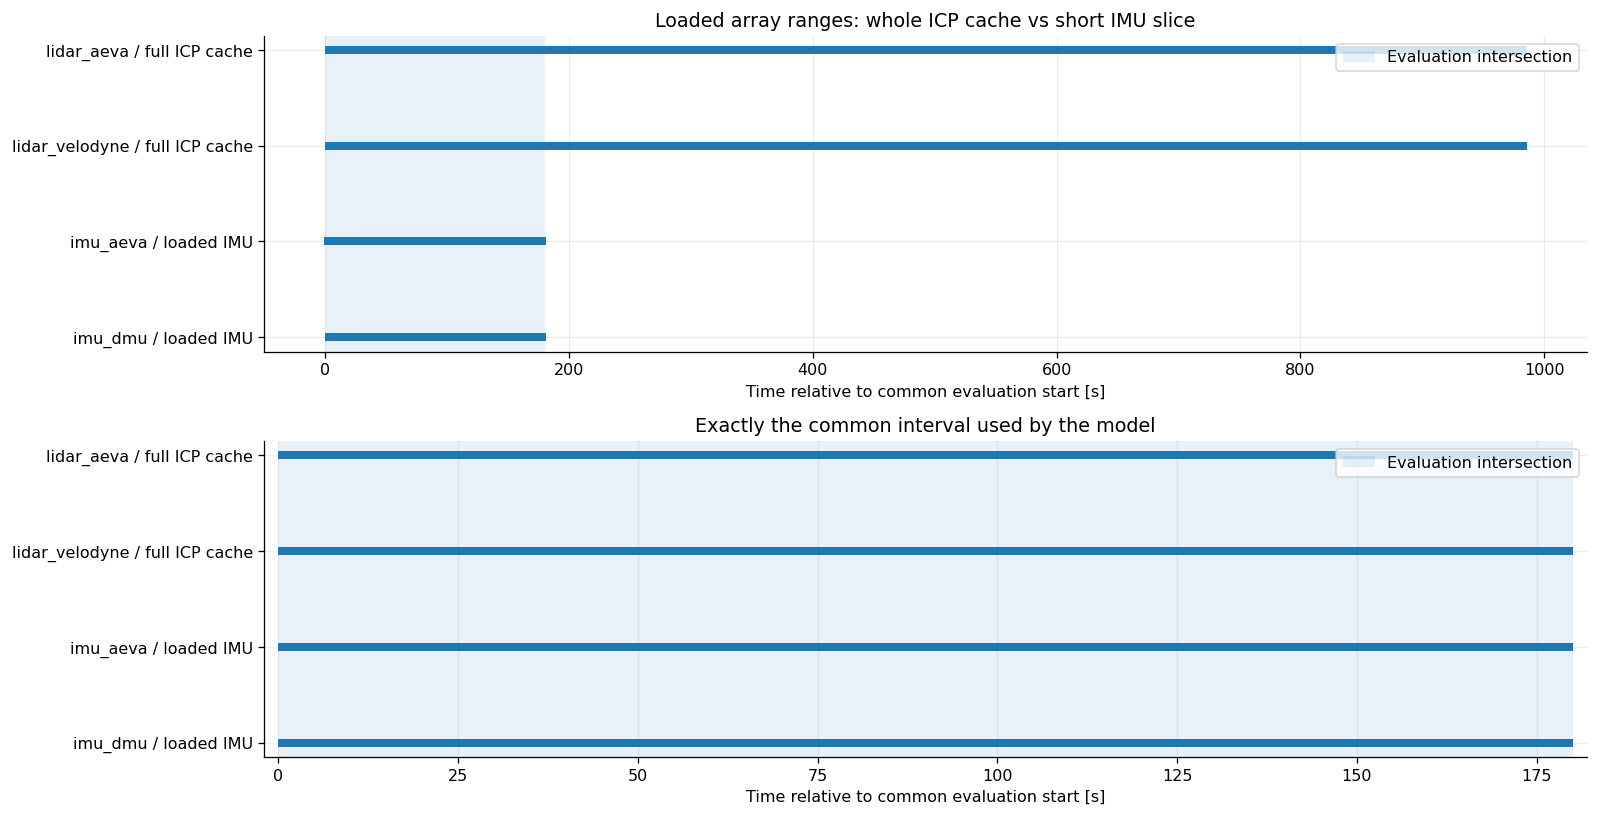

COMMON evaluation: 180.000 s; start/end UTC ns: 1733248461986694000, 1733248641986694000


In [7]:
# Full LiDAR caches vs the intentionally clipped IMU reads.
coverage_sources = [(f"{key} / loaded IMU", imu_ns[key]) for key in imu_ns]
coverage_sources += [(f"{key} / full ICP cache", lidar_ns[key]) for key in lidar_ns]
fig, axs = plt.subplots(2, 1, figsize=(14, 7.2), sharey=True)
shared = (common_end-common_start)*1e-9
for ax, clip in zip(axs, (False, True)):
    for j, (name, ns) in enumerate(coverage_sources):
        t0, t1 = int(ns[0]), int(ns[-1])
        if clip:
            t0, t1 = max(t0, common_start), min(t1, common_end)
        if t1 >= t0:
            ax.hlines(j, (t0-common_start)*1e-9, (t1-common_start)*1e-9, lw=5)
    ax.axvspan(0, shared, alpha=.10, label="Evaluation intersection")
    ax.set(yticks=range(len(coverage_sources)), yticklabels=[name for name, _ in coverage_sources],
           xlabel="Time relative to common evaluation start [s]")
    ax.legend(loc="upper right")
axs[0].set_title("Loaded array ranges: whole ICP cache vs short IMU slice")
axs[1].set_title("Exactly the common interval used by the model")
axs[1].set_xlim(-2, shared+2)
finish_plot(fig, "01_full_vs_evaluation_coverage.png")
print(f"COMMON evaluation: {shared:.3f} s; start/end UTC ns: {common_start}, {common_end}")

,domain,sensor,role,samples_min,samples_max,span_min_s,span_median_s,worst_start_gap_s,worst_end_gap_s,worst_dt_ms
0,boreas_four,accel_imu_aeva,imu,500,500,4.9888,4.9900,0.0024,0.0090,14.4439
1,boreas_four,accel_imu_dmu,imu,700,700,4.9949,4.9949,0.0044,0.0025,10.0002
2,boreas_four,gyro_imu_aeva,imu,500,500,4.9888,4.9900,0.0024,0.0090,14.4439
3,boreas_four,gyro_imu_dmu,imu,700,700,4.9949,4.9949,0.0044,0.0025,10.0002
4,boreas_four,lidar_aeva,lidar,49,49,4.8995,4.9000,0.0130,0.0875,100.0320
5,boreas_four,lidar_velodyne,lidar,47,48,4.8729,4.8794,0.0940,0.0985,108.8862
6,kaist,accel,imu,500,501,4.9898,4.9898,0.0099,0.0100,11.5254
7,kaist,gyro,imu,500,501,4.9898,4.9898,0.0099,0.0100,11.5254
8,kaist,lidar,lidar,48,49,4.8400,4.9400,0.0900,0.0900,110.0006
9,kaist,lidar_right,lidar,48,49,4.8400,4.9400,0.1000,0.1000,110.0001


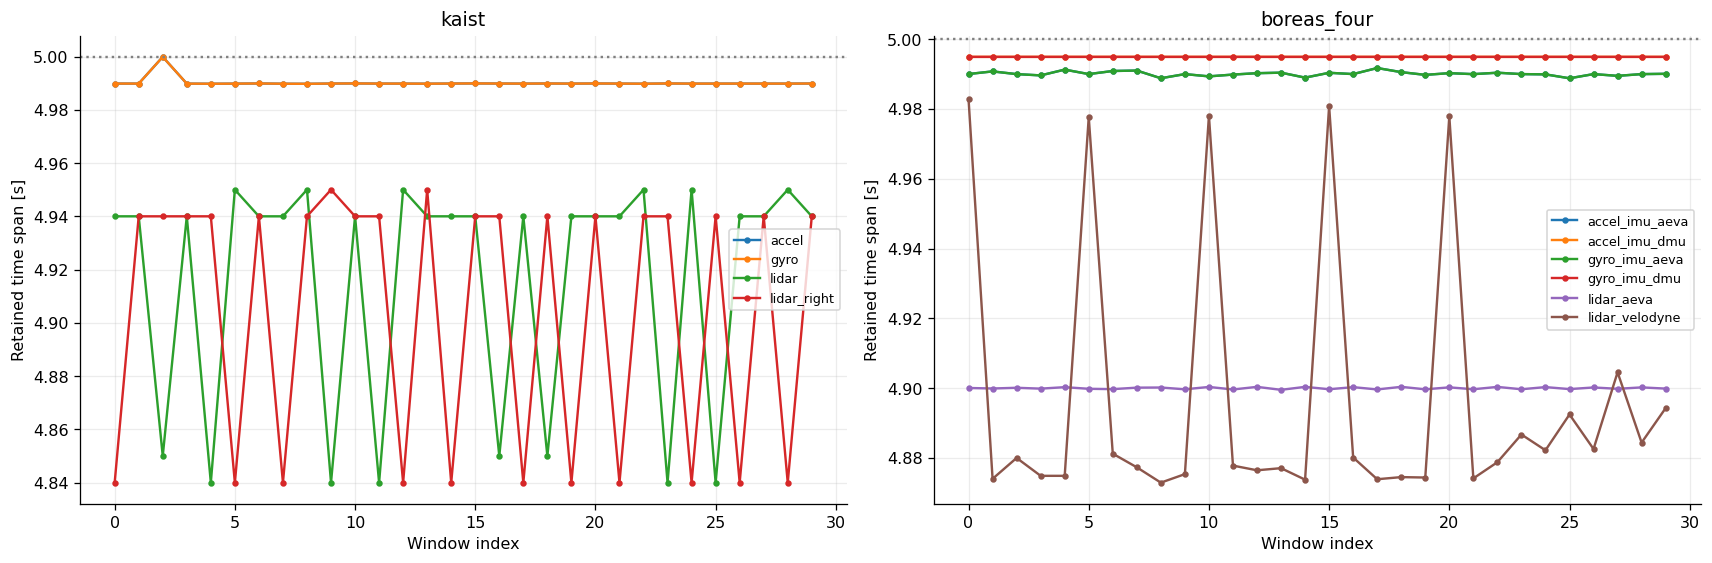

In [8]:
coverage_rows = []
for domain in ("kaist", "boreas_four"):
    for wi, w in enumerate(DOMAIN_WINDOWS[domain]):
        for name, stream in w.streams.items():
            times = stream.timestamps[0].detach().cpu().double().numpy()
            is_lidar = kind_of(w.metadata[name]) == "lidar"
            starts = (stream.interval_start_timestamps[0].detach().cpu().double().numpy()
                      if is_lidar else times)
            dts = np.diff(times)
            first, last = float(np.min(starts)), float(np.max(times))
            coverage_rows.append(dict(domain=domain, window=wi, sensor=name, role="lidar" if is_lidar else "imu",
                n=len(times), first_s=first, last_s=last, span_s=last-first,
                missing_start_s=max(0., first), missing_end_s=max(0., WINDOW_DURATION_S-last),
                median_dt_ms=float(np.median(dts)*1e3) if len(dts) else np.nan,
                max_dt_ms=float(np.max(dts)*1e3) if len(dts) else np.nan))
window_coverage = pd.DataFrame(coverage_rows)
assert (window_coverage.first_s >= -1e-3).all() and (window_coverage.last_s <= WINDOW_DURATION_S+1e-3).all()
coverage_table = window_coverage.groupby(["domain", "sensor", "role"], as_index=False).agg(
    samples_min=("n", "min"), samples_max=("n", "max"),
    span_min_s=("span_s", "min"), span_median_s=("span_s", "median"),
    worst_start_gap_s=("missing_start_s", "max"), worst_end_gap_s=("missing_end_s", "max"),
    worst_dt_ms=("max_dt_ms", "max"))
display(coverage_table.round(4))
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, domain in zip(axs, ("kaist", "boreas_four")):
    sub = window_coverage[window_coverage.domain == domain]
    for sensor, g in sub.groupby("sensor"):
        ax.plot(g.window, g.span_s, marker=".", label=sensor)
    ax.axhline(WINDOW_DURATION_S, c="gray", ls=":")
    ax.set(title=domain, xlabel="Window index", ylabel="Retained time span [s]")
    ax.legend(fontsize=8)
finish_plot(fig, "02_real_window_span_by_sensor.png")
if SAVE_PLOTS: window_coverage.to_csv(OUT / "window_coverage_and_gaps.csv", index=False)

## 4. Sensor-motion distributions, frames and IMU–LiDAR consistency

First quantify excitation **per physical window**, not only globally. We compare the distributions of angular velocity, linear velocity, and LiDAR edge durations. We do **not** interpret differences between a KAIST sensor-local axis and a Boreas sensor-local axis as physical differences before transforming into a common body frame.

In [9]:
def raw_feature_arrays(window):
    result={}
    for name,stream in window.streams.items():
        role=kind_of(window.metadata[name]);key=window.metadata[name].calibration_key
        vals=stream.values[0].detach().cpu().double().numpy()
        times=stream.timestamps[0].detach().cpu().double().numpy()
        tag=f"{key}/{role}"
        if role in ("gyro","accel"):
            result[tag+"/norm"]=np.linalg.norm(vals,axis=1)
            for axis,letter in enumerate("xyz"):
                result[tag+f"/{letter}"]=vals[:,axis]
        elif role=="lidar":
            rotvec=Rot.from_matrix(vals[:,:3,:3]).as_rotvec()
            t=np.linalg.norm(vals[:,:3,3],axis=1)
            a=np.rad2deg(np.linalg.norm(rotvec,axis=1))
            dt=times-stream.interval_start_timestamps[0].detach().cpu().numpy().astype(float)
            result[tag+"/translation_m"]=t
            result[tag+"/rotation_deg"]=a
            result[tag+"/translation_rate_mps"]=t/dt
            result[tag+"/rotation_rate_degps"]=a/dt
            result[tag+"/edge_duration_s"]=dt
        if len(times)>1:result[tag+"/sample_dt_s"]=np.diff(times)
    return result

RAW_VALUES={}
for domain,windows in DOMAIN_WINDOWS.items():
    combined={}
    for window in windows:
        for name, vals in raw_feature_arrays(window).items():
            combined.setdefault(name,[]).append(vals)
    RAW_VALUES[domain]={name:np.concatenate(chunks) for name,chunks in combined.items()}

rows=[]
for domain,features in RAW_VALUES.items():
    for feature,values in features.items():
        finite=values[np.isfinite(values)]
        rows.append(dict(domain=domain,feature=feature,n=len(finite),mean=np.mean(finite),
                         std=np.std(finite),p50=np.median(finite),p90=np.percentile(finite,90),
                         p99=np.percentile(finite,99),maximum=np.max(finite)))
raw_table=pd.DataFrame(rows)
display(raw_table.round(5))
if SAVE_PLOTS:raw_table.to_csv(OUT/"raw_sensor_statistics.csv",index=False)

,domain,feature,n,mean,std,p50,p90,p99,maximum
0,kaist,imu/gyro/norm,15001,0.11203,0.09933,0.07520,0.25568,0.42261,0.45296
1,kaist,imu/gyro/x,15001,-0.00432,0.04173,-0.00353,0.04407,0.10488,0.20700
2,kaist,imu/gyro/y,15001,-0.00116,0.03880,-0.00054,0.02772,0.11118,0.42731
3,kaist,imu/gyro/z,15001,0.05224,0.12814,0.01953,0.23311,0.41541,0.44689
4,kaist,imu/gyro/sample_dt_s,14971,0.01000,0.00004,0.01000,0.01004,0.01007,0.01153
...,...,...,...,...,...,...,...,...,...
145,boreas_four,lidar_aeva/lidar/rotation_deg,1470,0.67685,0.90224,0.29998,1.94015,4.14644,4.48796
146,boreas_four,lidar_aeva/lidar/translation_rate_mps,1470,7.04477,4.17663,7.71638,11.90095,15.96584,17.29321
147,boreas_four,lidar_aeva/lidar/rotation_rate_degps,1470,6.76850,9.02243,2.99974,19.39709,41.46142,44.88452
148,boreas_four,lidar_aeva/lidar/edge_duration_s,1470,0.10000,0.00001,0.10000,0.10002,0.10003,0.10003


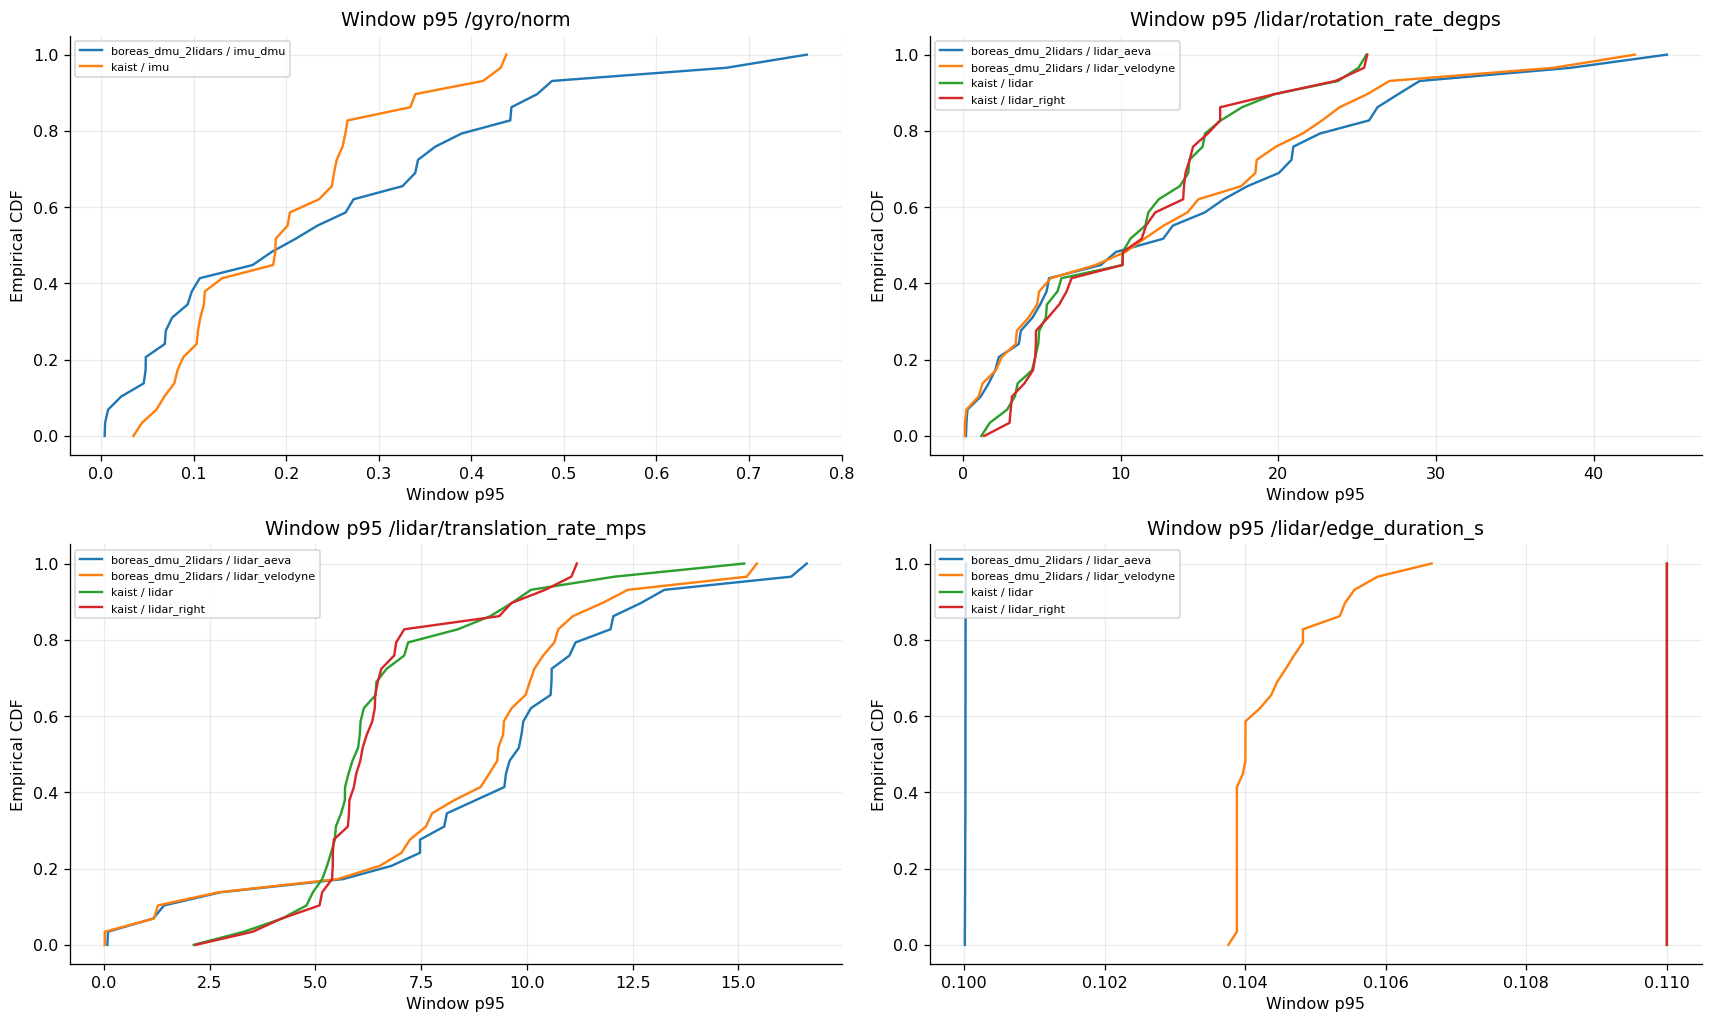

Note: 'good' motion excitation must be tested against correction quality, not presumed from these plots.


In [10]:
motion_rows = []
for domain in ("kaist", "boreas_dmu_2lidars"):
    for wi, w in enumerate(DOMAIN_WINDOWS[domain]):
        metrics = raw_feature_arrays(w)
        for name, values in metrics.items():
            if name.endswith(("/gyro/norm", "/lidar/rotation_rate_degps", "/lidar/translation_rate_mps", "/lidar/edge_duration_s")):
                finite = np.asarray(values, float)
                finite = finite[np.isfinite(finite)]
                if finite.size:
                    motion_rows.append(dict(domain=domain, window=wi, metric=name, median=float(np.median(finite)),
                        p95=float(np.percentile(finite,95)), n=len(finite)))
motion_table = pd.DataFrame(motion_rows)
metrics_to_plot = ("/gyro/norm", "/lidar/rotation_rate_degps", "/lidar/translation_rate_mps", "/lidar/edge_duration_s")
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
for ax, suffix in zip(axs.flat, metrics_to_plot):
    subset = motion_table[motion_table.metric.str.endswith(suffix)]
    for (domain, metric), group in subset.groupby(["domain", "metric"]):
        vals = np.sort(group.p95.to_numpy(float))
        ax.plot(vals, np.linspace(0,1,len(vals)), label=f"{domain} / {metric.split('/')[0]}")
    ax.set(title=f"Window p95 {suffix}", xlabel="Window p95", ylabel="Empirical CDF")
    ax.legend(fontsize=7)
finish_plot(fig, "03_kaist_vs_boreas_motion_window_cdf.png")
print("Note: 'good' motion excitation must be tested against correction quality, not presumed from these plots.")
if SAVE_PLOTS: motion_table.to_csv(OUT / "physical_motion_per_window.csv", index=False)

In [11]:
# Verify nominal IMU-to-LiDAR frame geometry in both datasets (not a claim of correct GT).
rig_rows = []
for domain in ("kaist", "boreas_dmu_2lidars"):
    w = DOMAIN_WINDOWS[domain][0]
    for imu_key in keys_of_kind(w, "gyro"):
        for lidar_key in keys_of_kind(w, "lidar"):
            TI = w.current_calibration[imu_key].transform[0].detach().cpu().numpy()
            TL = w.current_calibration[lidar_key].transform[0].detach().cpu().numpy()
            T_I_L = np.linalg.solve(TI, TL)
            rig_rows.append(dict(domain=domain, imu=imu_key, lidar=lidar_key,
                nominal_rot_deg=np.rad2deg(Rot.from_matrix(T_I_L[:3,:3]).magnitude()),
                baseline_m=np.linalg.norm(T_I_L[:3,3])))
display(pd.DataFrame(rig_rows).round(4))

,domain,imu,lidar,nominal_rot_deg,baseline_m
0,kaist,imu,lidar,139.3885,3.6670
1,kaist,imu,lidar_right,139.2400,3.6739
2,boreas_dmu_2lidars,imu_dmu,lidar_velodyne,179.9837,0.2800
3,boreas_dmu_2lidars,imu_dmu,lidar_aeva,179.9372,0.4925


,domain,sensor,raw_ax,raw_ay,raw_az,body_ax,body_ay,body_az,accel_norm_med,gyro_body_p95
0,boreas_four,imu_aeva,0.285,0.032,9.814,-0.045,0.263,9.816,9.979,0.195
1,boreas_four,imu_dmu,-0.106,-0.191,-9.780,-0.082,0.195,9.779,9.923,0.197
2,kaist,imu,-0.059,0.159,9.819,-0.059,0.159,9.819,9.889,0.188


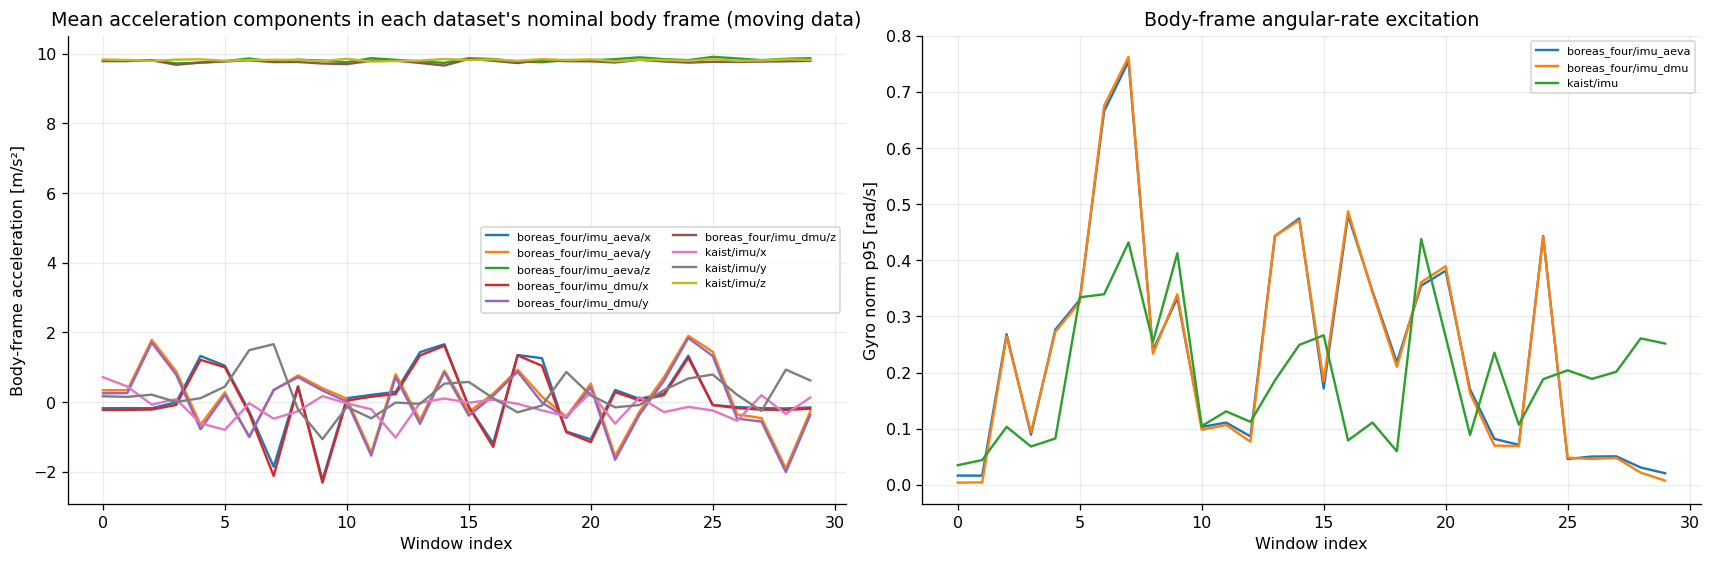

In [12]:
# Raw sensor-local IMU axes are NOT comparable before inspecting nominal mounting rotation.
# These are descriptive accelerometer means during motion, not a certified gravity estimate.
body_imu_rows = []
for domain in ("kaist", "boreas_four"):
    for wi, w in enumerate(DOMAIN_WINDOWS[domain]):
        for key in keys_of_kind(w,"gyro"):
            groups=role_streams(w)[key]
            R_B_I=w.current_calibration[key].transform[0,:3,:3].detach().cpu().numpy()
            a=w.streams[groups["accel"]].values[0].detach().cpu().numpy()
            g=w.streams[groups["gyro"]].values[0].detach().cpu().numpy()
            a_body=a@R_B_I.T
            g_body=g@R_B_I.T
            body_imu_rows.append(dict(domain=domain,window=wi,sensor=key,
                raw_ax=float(np.mean(a[:,0])),raw_ay=float(np.mean(a[:,1])),raw_az=float(np.mean(a[:,2])),
                body_ax=float(np.mean(a_body[:,0])),body_ay=float(np.mean(a_body[:,1])),body_az=float(np.mean(a_body[:,2])),
                accel_norm_med=float(np.median(np.linalg.norm(a,axis=1))),
                gyro_body_p95=float(np.percentile(np.linalg.norm(g_body,axis=1),95))))
body_imu=pd.DataFrame(body_imu_rows)
display(body_imu.groupby(["domain","sensor"],as_index=False)[
    ["raw_ax","raw_ay","raw_az","body_ax","body_ay","body_az","accel_norm_med","gyro_body_p95"]].median().round(3))
fig,axs=plt.subplots(1,2,figsize=(15,5))
for (domain,sensor),part in body_imu.groupby(["domain","sensor"]):
    for j,axis in enumerate("xyz"):
        axs[0].plot(part.window,part[f"body_a{axis}"],label=f"{domain}/{sensor}/{axis}")
    axs[1].plot(part.window,part.gyro_body_p95,label=f"{domain}/{sensor}")
axs[0].set(title="Mean acceleration components in each dataset's nominal body frame (moving data)",
           xlabel="Window index",ylabel="Body-frame acceleration [m/s²]")
axs[1].set(title="Body-frame angular-rate excitation",xlabel="Window index",ylabel="Gyro norm p95 [rad/s]")
axs[0].legend(fontsize=7,ncol=2);axs[1].legend(fontsize=7)
finish_plot(fig,"03b_imu_body_frame_axis_audit.png")
if SAVE_PLOTS:body_imu.to_csv(OUT/"imu_frame_and_gravity_diagnostics.csv",index=False)

Gyro-vs-LiDAR | kaist:   0%|          | 0/30 [00:00<?, ?it/s]

Gyro-vs-LiDAR | boreas_dmu_2lidars:   0%|          | 0/30 [00:00<?, ?it/s]

,domain,imu,lidar,shift_s,median_disagreement_deg,inverse_control_deg,total_moving_edges
0,boreas_dmu_2lidars,imu_dmu,lidar_aeva,-0.05,0.2004,1.0648,631
1,boreas_dmu_2lidars,imu_dmu,lidar_aeva,0.00,0.1280,1.0669,655
2,boreas_dmu_2lidars,imu_dmu,lidar_aeva,0.05,0.0535,1.0566,657
3,boreas_dmu_2lidars,imu_dmu,lidar_velodyne,-0.05,0.1078,1.0542,651
4,boreas_dmu_2lidars,imu_dmu,lidar_velodyne,0.00,0.0461,1.0485,657
5,boreas_dmu_2lidars,imu_dmu,lidar_velodyne,0.05,0.1036,1.0628,645
6,kaist,imu,lidar,-0.05,0.1150,1.0154,758
7,kaist,imu,lidar,0.00,0.1338,1.0187,764
8,kaist,imu,lidar,0.05,0.1707,0.9055,760
9,kaist,imu,lidar_right,-0.05,0.1207,0.9960,752


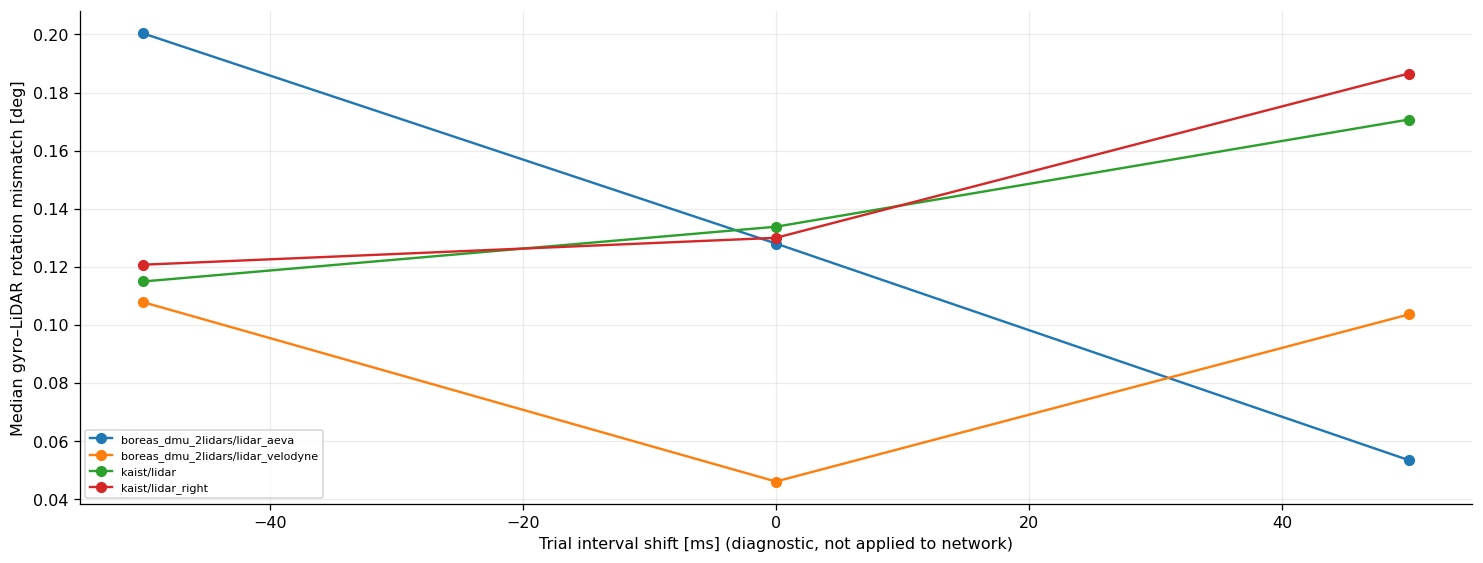

In [13]:
# Compare integrated gyroscope rotations with independent LiDAR rotations in the IMU frame.
# The inverse-edge result is a convention control. This is a first-order diagnostic, not clock calibration.
def integrated_gyro(t, w, start, end, step_s=.01):
    if start < t[0] or end > t[-1] or end <= start:
        return None
    n = max(1, int(np.ceil((end-start)/step_s)))
    dt = (end-start)/n
    ts = start+(np.arange(n)+.5)*dt
    omega = np.column_stack([np.interp(ts, t, w[:,j]) for j in range(3)])
    r = Rot.identity()
    for v in omega: r = r * Rot.from_rotvec(v*dt)
    return r

def consistency_for_window(w, wi, domain, shifts=(-.05,0.,.05), max_edges=30):
    groups = role_streams(w)
    rows=[]
    for imu_key in keys_of_kind(w, "gyro"):
        g = w.streams[groups[imu_key]["gyro"]]
        tg = g.timestamps[0].detach().cpu().numpy().astype(float)
        wg = g.values[0].detach().cpu().numpy().astype(float)
        TI = w.current_calibration[imu_key].transform[0].detach().cpu().numpy()
        for lidar_key in keys_of_kind(w, "lidar"):
            l = w.streams[groups[lidar_key]["lidar"]]
            starts = l.interval_start_timestamps[0].detach().cpu().numpy().astype(float)
            ends = l.timestamps[0].detach().cpu().numpy().astype(float)
            rotations = l.values[0,:,:3,:3].detach().cpu().numpy().astype(float)
            TL = w.current_calibration[lidar_key].transform[0].detach().cpu().numpy()
            R_I_L = np.linalg.solve(TI, TL)[:3,:3]
            for shift in shifts:
                forward=[]; inverse=[]; moving=[]
                for k in np.linspace(0,len(ends)-1,min(len(ends),max_edges),dtype=int):
                    gyro_delta = integrated_gyro(tg,wg,starts[k]+shift,ends[k]+shift)
                    if gyro_delta is None: continue
                    lidar_delta = Rot.from_matrix(R_I_L @ rotations[k] @ R_I_L.T)
                    forward.append(np.rad2deg((gyro_delta.inv()*lidar_delta).magnitude()))
                    inverse.append(np.rad2deg((gyro_delta.inv()*lidar_delta.inv()).magnitude()))
                    moving.append(np.rad2deg(gyro_delta.magnitude()) >= .10)
                if forward:
                    m=np.asarray(moving, bool)
                    rows.append(dict(domain=domain,window=wi,imu=imu_key,lidar=lidar_key,shift_s=shift,
                        n=len(forward), moving_n=int(m.sum()),
                        discrepancy_deg=float(np.median(np.asarray(forward)[m])) if m.any() else np.nan,
                        inverse_discrepancy_deg=float(np.median(np.asarray(inverse)[m])) if m.any() else np.nan))
    return rows

consistency_rows=[]
if RUN_CONSISTENCY_SWEEP:
    for domain in DOMAINS_PRIMARY:
        for wi in tqdm(range(len(DOMAIN_WINDOWS[domain])), desc=f"Gyro-vs-LiDAR | {domain}"):
            consistency_rows += consistency_for_window(DOMAIN_WINDOWS[domain][wi], wi, domain)
consistency = pd.DataFrame(consistency_rows)
if not consistency.empty:
    display(consistency.groupby(["domain","imu","lidar","shift_s"], as_index=False).agg(
        median_disagreement_deg=("discrepancy_deg","median"),
        inverse_control_deg=("inverse_discrepancy_deg","median"),
        total_moving_edges=("moving_n","sum")).round(4))
    fig, ax=plt.subplots(figsize=(13,5))
    for (domain,lidar),part in consistency.groupby(["domain","lidar"]):
        g=part.groupby("shift_s").discrepancy_deg.median()
        ax.plot(g.index.to_numpy()*1000,g.to_numpy(),"-o",label=f"{domain}/{lidar}")
    ax.set(xlabel="Trial interval shift [ms] (diagnostic, not applied to network)",
           ylabel="Median gyro–LiDAR rotation mismatch [deg]")
    ax.legend(fontsize=7)
    finish_plot(fig,"04_gyro_lidar_rotation_consistency.png")
    if SAVE_PLOTS: consistency.to_csv(OUT/"gyro_lidar_consistency_by_window.csv",index=False)

### 4.1 Boreas ICP versus reference relative motion, by window

This is an **offline source-quality diagnosis**. Its Applanix/GNSS-derived reference is not an independent LiDAR odometry input and is never used to compute the baseline model predictions. Compare the *per-edge* errors alongside FM performance later, rather than blaming ICP drift without evidence.

,rot_median,rot_p95_over_windows,trans_median,n_windows
lidar,,,,
lidar_aeva,0.1189,0.2594,0.0269,30
lidar_velodyne,0.0391,0.0948,0.0324,30


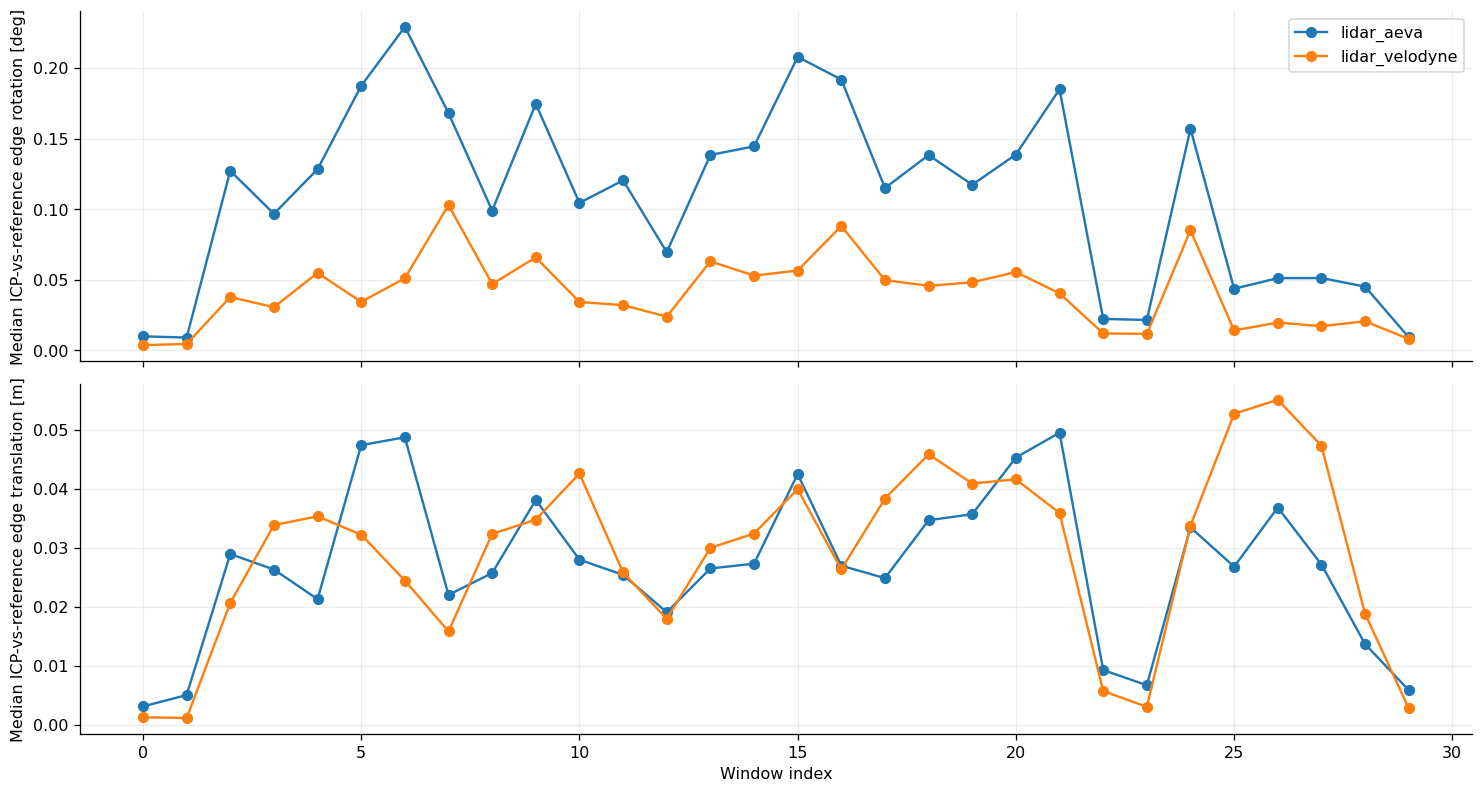

In [14]:
BOREAS_GT_BY_SOURCE = {}
quality_rows = []
if RUN_BOREAS_GT_QUALITY:
    for key, source in (("lidar_velodyne","velodyne"),("lidar_aeva","aeva")):
        BOREAS_GT_BY_SOURCE[key] = boreas_sequence.lidar_poses(source=source)
    for wi, w in enumerate(DOMAIN_WINDOWS["boreas_dmu_2lidars"]):
        for key, gt in BOREAS_GT_BY_SOURCE.items():
            stream = w.streams[key]
            absolute_start_ns = common_start + np.rint(stream.interval_start_timestamps[0].numpy()*1e9).astype(np.int64) + int(round(boreas_window_starts[wi]*1e9))
            absolute_end_ns = common_start + np.rint(stream.timestamps[0].numpy()*1e9).astype(np.int64) + int(round(boreas_window_starts[wi]*1e9))
            query = np.unique(np.concatenate([absolute_start_ns, absolute_end_ns]))
            try:
                matched = gt.match(query, tolerance_s=.15, interpolate=True, max_gap_s=.4)
                gt_edges = np.linalg.solve(matched[np.searchsorted(query,absolute_start_ns)],
                                           matched[np.searchsorted(query,absolute_end_ns)])
            except (ValueError, IndexError) as exc:
                print(f"SKIP GT comparison: {key}, window {wi}: {exc}")
                continue
            icp = stream.values[0].numpy()
            err=np.linalg.solve(gt_edges, icp)
            rotation_deg=np.rad2deg(Rot.from_matrix(err[:,:3,:3]).magnitude())
            translation_m=np.linalg.norm(err[:,:3,3],axis=1)
            quality_rows.append(dict(domain="boreas_dmu_2lidars",window=wi,lidar=key,n=len(icp),
                rot_error_med_deg=float(np.median(rotation_deg)),rot_error_p95_deg=float(np.percentile(rotation_deg,95)),
                trans_error_med_m=float(np.median(translation_m)),trans_error_p95_m=float(np.percentile(translation_m,95))))
quality = pd.DataFrame(quality_rows)
if not quality.empty:
    display(quality.groupby("lidar").agg(rot_median=("rot_error_med_deg","median"),
        rot_p95_over_windows=("rot_error_p95_deg","median"),
        trans_median=("trans_error_med_m","median"),n_windows=("window","size")).round(4))
    fig,axs=plt.subplots(2,1,figsize=(13,7),sharex=True)
    for key,part in quality.groupby("lidar"):
        axs[0].plot(part.window,part.rot_error_med_deg,"-o",label=key)
        axs[1].plot(part.window,part.trans_error_med_m,"-o",label=key)
    axs[0].set(ylabel="Median ICP-vs-reference edge rotation [deg]")
    axs[1].set(xlabel="Window index",ylabel="Median ICP-vs-reference edge translation [m]")
    axs[0].legend();finish_plot(fig,"05_independent_icp_quality_per_window.png")
    if SAVE_PLOTS: quality.to_csv(OUT/"boreas_icp_vs_reference_quality.csv",index=False)

## 5. Frozen models, input tokens, and representation checks

Both checkpoints use the same geometry processing and tokenization. A network with permutation/masking support is **not necessarily invariant to sensor count or token-density changes**. We quantify the physical token mixture and then run controlled ablations without altering the LiDAR measurements.

In [15]:
model_config=PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8,d_model=128,n_heads=8,num_layers=12,
                                  dim_feedforward=512,dropout=0.0,num_summary_tokens=1,activation="gelu"),
    mlp=MLPConfig(hidden_dims=(256,128),output_dim=128,activation="gelu",dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8,dropout=0.0,calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0,hidden_dims=(128,64),activation="gelu",dropout=0.0))
flow_config=PooledCalibrationFlowConfig(backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_STEPS,method=FM_METHOD),
    freeze_backbone_initially=False)
fm=PooledCalibrationFlowModel(flow_config.backbone,**flow_config.model_kwargs()).to(DEVICE,dtype=MODEL_DTYPE)
checkpoint_path=FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT/FM_CHECKPOINT
fm_metadata=load_training_checkpoint(checkpoint_path,model=fm,map_location=DEVICE,restore_rng_state=False)
fm.eval().requires_grad_(False)
MODELS={"FM .11":fm}
if RUN_REGRESSION:
    regression=PooledCalibrationModel(model_config).to(DEVICE,dtype=MODEL_DTYPE)
    ckpt=REGRESSION_CHECKPOINT if REGRESSION_CHECKPOINT.is_absolute() else ROOT/REGRESSION_CHECKPOINT
    regression_metadata=load_training_checkpoint(ckpt,model=regression,map_location=DEVICE,restore_rng_state=False)
    regression.eval().requires_grad_(False)
    MODELS["Regression 2.26"]=regression
geometry_processor=GeometryProcessor()

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

def tokenize_window(window,states):
    if set(states)!=set(window.current_calibration):raise ValueError("state/window calibration mismatch")
    canonical=geometry_processor(window.streams,window.metadata,states)
    keys=tuple(window.current_calibration)
    tokens=Tokenizer(measurement_dim=6,calibration_keys=keys)(canonical,observability=None)
    context={key:calibration_state_to_context(states[key]) for key in keys}
    if tokens.x.ndim!=3 or tokens.x.shape[-1]!=8 or not torch.isfinite(tokens.x).all():
        raise RuntimeError("Invalid/nonfinite canonical model tokens")
    return tokens,context

@torch.inference_mode()
def model_predict(model,window,states):
    tokens,ctx=tokenize_window(window,states)
    pred=model(tokens,ctx,num_steps=FM_STEPS,method=FM_METHOD) if isinstance(model,PooledCalibrationFlowModel) else model(tokens,ctx)
    if set(pred.predictions)!=set(states):raise RuntimeError("Incomplete calibration predictions")
    return pred

print("Model checkpoints loaded; frozen parameter counts:",
      {name:sum(p.numel() for p in model.parameters()) for name,model in MODELS.items()})

Model checkpoints loaded; frozen parameter counts: {'FM .11': 2555399, 'Regression 2.26': 2554505}


,domain,physical_sensors,imu_tokens,lidar_tokens,total_tokens,lidar_fraction
0,kaist,3,1000,97,1097,0.0884
1,boreas_dmu_2lidars,3,1400,97,1497,0.0648
2,boreas_aevaimu_2lidars,3,1000,97,1097,0.0884
3,boreas_2imu_velodyne,3,2400,48,2448,0.0196
4,boreas_2imu_aeva_lidar,3,2400,49,2449,0.0200
5,boreas_four,4,2400,97,2497,0.0388


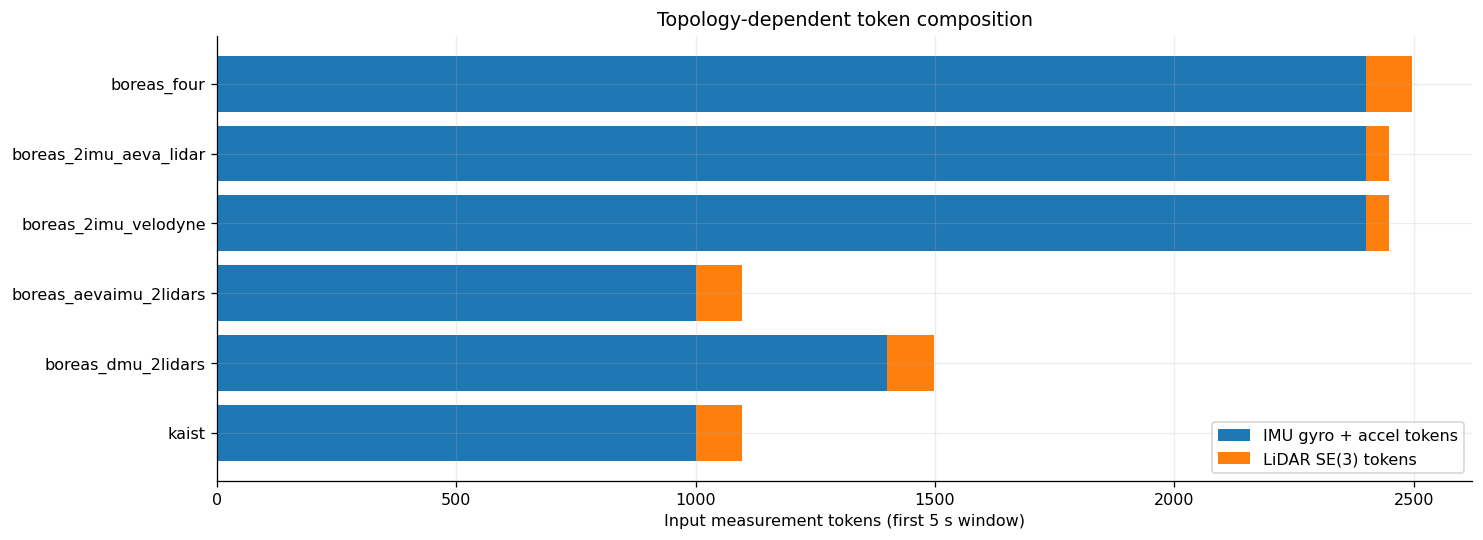

In [16]:
# First-window input-token counts, by stream and topology. IMUs have TWO streams per sensor.
counts=[]
for domain in DOMAIN_WINDOWS:
    w=DOMAIN_WINDOWS[domain][0]
    imu_tokens=sum(s.values.shape[1] for name,s in w.streams.items() if kind_of(w.metadata[name]) != "lidar")
    lidar_tokens=sum(s.values.shape[1] for name,s in w.streams.items() if kind_of(w.metadata[name]) == "lidar")
    counts.append(dict(domain=domain,physical_sensors=len(w.current_calibration),
        imu_tokens=imu_tokens,lidar_tokens=lidar_tokens,total_tokens=imu_tokens+lidar_tokens,
        lidar_fraction=lidar_tokens/(imu_tokens+lidar_tokens)))
composition=pd.DataFrame(counts)
display(composition.round(4))
fig,ax=plt.subplots(figsize=(13,4.8))
ax.barh(composition.domain,composition.imu_tokens,label="IMU gyro + accel tokens")
ax.barh(composition.domain,composition.lidar_tokens,left=composition.imu_tokens,label="LiDAR SE(3) tokens")
ax.set(xlabel="Input measurement tokens (first 5 s window)",title="Topology-dependent token composition")
ax.legend();finish_plot(fig,"06_topology_token_balance.png")
if SAVE_PLOTS: composition.to_csv(OUT/"token_composition.csv",index=False)

,domain,feature,mean,std,median
0,kaist,0,0.1218,0.5139,0.0035
1,kaist,1,0.0959,0.7798,0.0006
2,kaist,2,4.5051,4.8953,0.2177
3,kaist,3,0.0378,0.1550,0.0000
4,kaist,4,-0.0001,0.0034,0.0000
5,kaist,5,0.0001,0.0025,0.0000
6,kaist,6,2.5042,1.4416,2.5054
7,kaist,7,0.6336,0.6405,1.0000
8,boreas_dmu_2lidars,0,-0.1784,0.7957,-0.0023
9,boreas_dmu_2lidars,1,0.0382,0.5043,0.0004


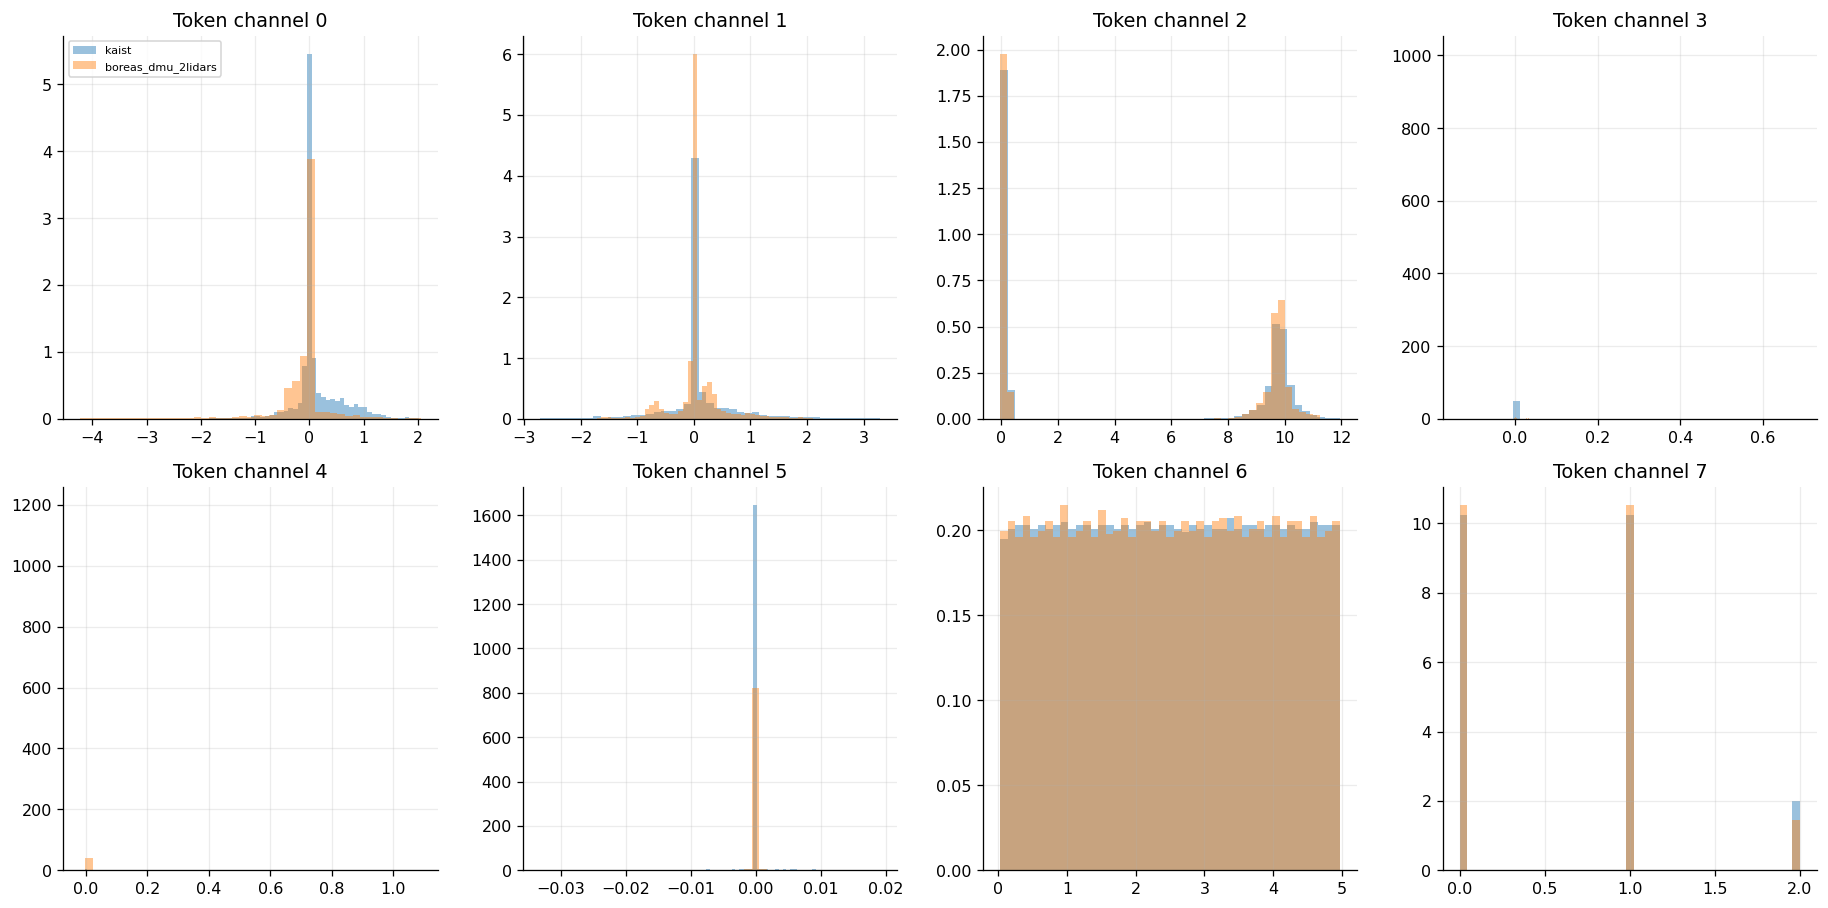

In [17]:
# Token statistics at the nominal reference: do not infer semantic channel labels without tokenizer code.
token_rows=[]; token_arrays={}
if RUN_CROSS_DOMAIN_TOKEN_PLOTS:
    for domain in DOMAINS_PRIMARY:
        samples=[]
        for wi in sorted({0,len(DOMAIN_WINDOWS[domain])//3,2*len(DOMAIN_WINDOWS[domain])//3,len(DOMAIN_WINDOWS[domain])-1}):
            w=to_device(DOMAIN_WINDOWS[domain][wi])
            tokens,_=tokenize_window(w,w.current_calibration)
            samples.append(tokens.x.detach().cpu().numpy().reshape(-1,8))
        vals=np.concatenate(samples,axis=0)
        token_arrays[domain]=vals
        for j in range(vals.shape[1]):
            token_rows.append(dict(domain=domain,feature=j,mean=float(vals[:,j].mean()),
                std=float(vals[:,j].std()),median=float(np.median(vals[:,j]))))
    display(pd.DataFrame(token_rows).round(4))
    fig,axs=plt.subplots(2,4,figsize=(16,8))
    for j,ax in enumerate(axs.flat):
        for domain, vals in token_arrays.items():
            x=vals[:,j]
            lo,hi=np.percentile(x,[.5,99.5])
            ax.hist(x[(x>=lo)&(x<=hi)],bins=45,alpha=.45,density=True,label=domain)
        ax.set(title=f"Token channel {j}")
        if j==0:ax.legend(fontsize=7)
    finish_plot(fig,"07_nominal_token_distributions.png")

## 6. Fresh single-window LiDAR corrections on **every** loaded window

Each case starts from the identical nominal calibration plus a left-multiplied X/Y/Z rotation fault on **one LiDAR only**. The IMU and other LiDAR remain healthy. Record actual error reduction **and** correction direction relative to the ideal left-applied update. Median over windows is reported separately by axis, never pooled with IMU errors. At 0° there is no meaningful correction cosine.

In [18]:
def states_clone(states):
    return {key:CalibrationState(transform=state.transform.clone(),time_offset=state.time_offset.clone())
            for key,state in states.items()}

def so3_error_deg(Ta,Tb):
    R=Tb[:,:3,:3]@Ta[:,:3,:3].transpose(-1,-2)
    skew=torch.stack((R[:,2,1]-R[:,1,2],R[:,0,2]-R[:,2,0],R[:,1,0]-R[:,0,1]),dim=1)
    return torch.rad2deg(torch.atan2(.5*torch.linalg.vector_norm(skew,dim=1),
                                    .5*(torch.diagonal(R,dim1=-2,dim2=-1).sum(dim=1)-1)))

def inject_rotation_fault(reference,key,angle_deg,axis):
    states=states_clone(reference)
    direction=np.eye(3)["xyz".index(axis)]
    rv=torch.as_tensor(direction,dtype=reference[key].transform.dtype,device=reference[key].transform.device).reshape(1,3)
    T=states[key].transform.clone()
    T[:,:3,:3]=so3_exp(rv*np.deg2rad(angle_deg))@T[:,:3,:3]
    states[key]=CalibrationState(transform=T,time_offset=states[key].time_offset.clone())
    assert np.isclose(float(so3_error_deg(T,reference[key].transform).item()),angle_deg,atol=.05)
    return states

def apply_single_rotation_update(states,pred,key,*,gain=1.0):
    updated=states_clone(states)
    old=states[key]
    T=old.transform.clone()
    step=pred.predictions[key].delta_xi[:,:3]*gain
    T[:,:3,:3]=so3_exp(step)@T[:,:3,:3]
    updated[key]=CalibrationState(transform=T,time_offset=old.time_offset.clone())
    return updated

def update_diagnostics(reference, before, after, pred, key):
    r=reference[key].transform[0,:3,:3].detach().cpu().numpy().astype(float)
    b=before[key].transform[0,:3,:3].detach().cpu().numpy().astype(float)
    a=after[key].transform[0,:3,:3].detach().cpu().numpy().astype(float)
    ideal=Rot.from_matrix(r@b.T).as_rotvec()
    actual=Rot.from_matrix(a@b.T).as_rotvec()
    ni,na=np.linalg.norm(ideal),np.linalg.norm(actual)
    before_err=float(so3_error_deg(before[key].transform,reference[key].transform).item())
    after_err=float(so3_error_deg(after[key].transform,reference[key].transform).item())
    return dict(initial_deg=before_err,final_deg=after_err,improvement_deg=before_err-after_err,
        predicted_step_deg=float(np.rad2deg(na)),
        cosine=float(ideal@actual/(ni*na)) if ni>1e-7 and na>1e-9 else np.nan,
        ideal_aligned_step_deg=float(np.rad2deg(ideal@actual/ni)) if ni>1e-7 else np.nan)

@torch.inference_mode()
def run_fresh_case(domain,wi,lidar,angle,axis,model_name,window_override=None):
    w=to_device(DOMAIN_WINDOWS[domain][wi]) if window_override is None else to_device(window_override)
    ref=w.current_calibration
    states=inject_rotation_fault(ref,lidar,angle,axis)
    prediction=model_predict(MODELS[model_name],w,states)
    corrected=apply_single_rotation_update(states,prediction,lidar)
    return dict(domain=domain,window=wi,lidar=lidar,angle_deg=angle,axis=axis,model=model_name,
                **update_diagnostics(ref,states,corrected,prediction,lidar))

In [19]:
from itertools import product
DIAG_INDICES={d:(list(range(len(DOMAIN_WINDOWS[d]))) if DIAG_WINDOW_INDICES is None
                 else sorted(i for i in set(DIAG_WINDOW_INDICES) if 0<=i<len(DOMAIN_WINDOWS[d])))
              for d in DOMAINS_PRIMARY}
fresh_rows=[]
if RUN_ALL_WINDOW_ONE_STEP:
    jobs=[]
    for domain in DOMAINS_PRIMARY:
        for wi in DIAG_INDICES[domain]:
            for key in keys_of_kind(DOMAIN_WINDOWS[domain][wi],"lidar"):
                for angle in DIAG_ANGLES_DEG:
                    for axis in (("z",) if angle==0 else DIAG_AXES):
                        for model in MODELS:
                            jobs.append((domain,wi,key,angle,axis,model))
    for args in tqdm(jobs, desc="Matched all-window, per-axis corrections"):
        fresh_rows.append(run_fresh_case(*args))
fresh=pd.DataFrame(fresh_rows)
if not fresh.empty:
    summary=fresh.groupby(["domain","lidar","model","axis","angle_deg"],as_index=False).agg(
        median_improvement_deg=("improvement_deg","median"),
        p10_improvement_deg=("improvement_deg",lambda x:x.quantile(.1)),
        p90_improvement_deg=("improvement_deg",lambda x:x.quantile(.9)),
        median_final_deg=("final_deg","median"),
        median_cosine=("cosine","median"),
        positive_fraction=("improvement_deg",lambda x:(x>0).mean()),n=("improvement_deg","size"))
    display(summary.round(3))
    if SAVE_PLOTS:
        fresh.to_csv(OUT/"fresh_one_step_all_windows_all_axes.csv",index=False)
        summary.to_csv(OUT/"fresh_one_step_summary.csv",index=False)

Matched all-window, per-axis corrections:   0%|          | 0/3120 [00:00<?, ?it/s]

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


,domain,lidar,model,axis,angle_deg,median_improvement_deg,p10_improvement_deg,p90_improvement_deg,median_final_deg,median_cosine,positive_fraction,n
0,boreas_dmu_2lidars,lidar_aeva,FM .11,x,15.0,5.322,0.824,9.624,9.678,0.847,0.900,30
1,boreas_dmu_2lidars,lidar_aeva,FM .11,x,45.0,24.960,9.880,32.232,20.040,0.912,1.000,30
2,boreas_dmu_2lidars,lidar_aeva,FM .11,x,90.0,31.537,20.355,43.519,58.463,0.740,0.967,30
3,boreas_dmu_2lidars,lidar_aeva,FM .11,x,130.0,-10.233,-20.391,4.416,140.233,0.025,0.167,30
4,boreas_dmu_2lidars,lidar_aeva,FM .11,y,15.0,-0.105,-1.215,0.780,15.105,0.116,0.467,30
...,...,...,...,...,...,...,...,...,...,...,...,...
99,kaist,lidar_right,Regression 2.26,z,0.0,-0.395,-1.348,-0.163,0.395,NaN,0.000,30
100,kaist,lidar_right,Regression 2.26,z,15.0,9.060,5.891,12.892,5.940,0.940,1.000,30
101,kaist,lidar_right,Regression 2.26,z,45.0,36.518,28.197,42.841,8.482,0.983,1.000,30
102,kaist,lidar_right,Regression 2.26,z,90.0,65.544,49.790,68.461,24.456,0.997,0.967,30


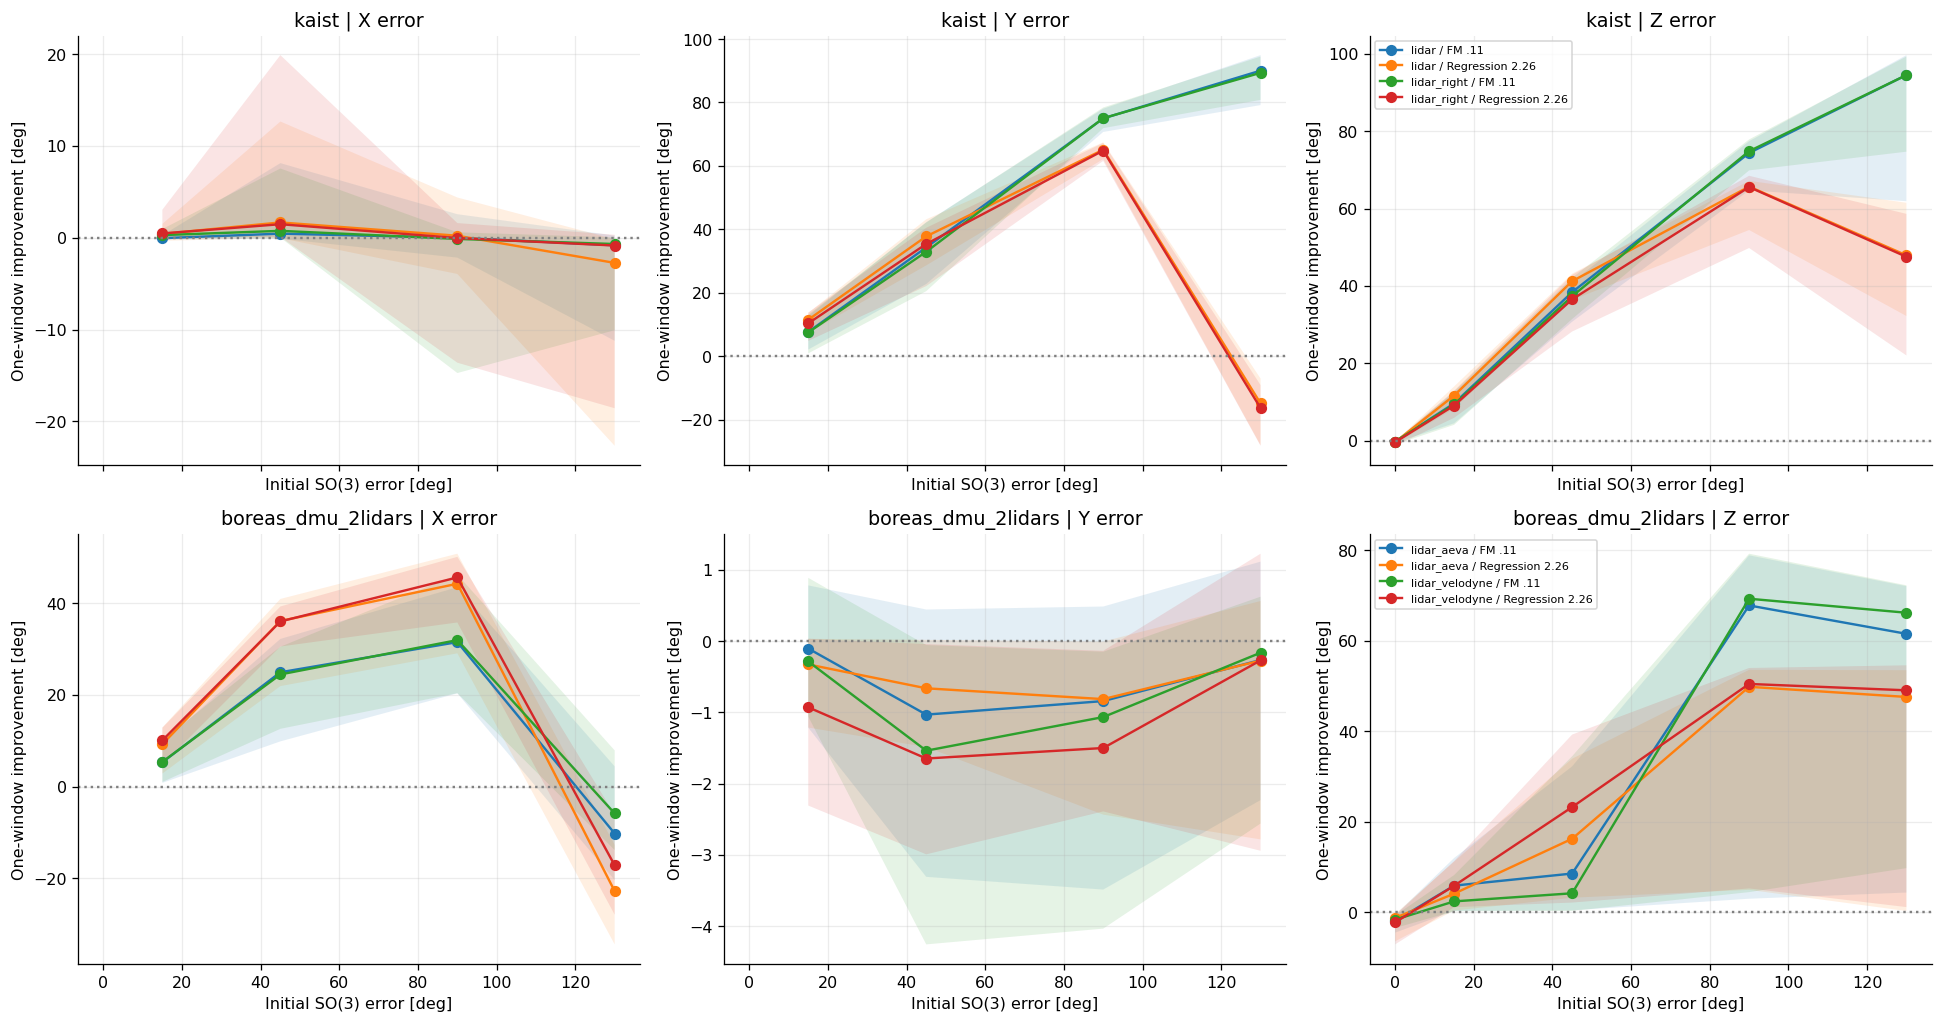

In [20]:
if not fresh.empty:
    fig,axs=plt.subplots(2,3,figsize=(17,9),sharex=True)
    for row,domain in enumerate(DOMAINS_PRIMARY):
        for col,axis in enumerate(DIAG_AXES):
            ax=axs[row,col]
            data=fresh[(fresh.domain==domain)&(fresh.axis==axis)]
            for (lidar,model),sub in data.groupby(["lidar","model"]):
                g=sub.groupby("angle_deg").improvement_deg
                med=g.median();lo=g.quantile(.1);hi=g.quantile(.9)
                label=f"{lidar} / {model}"
                ax.plot(med.index,med.values,"-o",label=label)
                ax.fill_between(med.index,lo.values,hi.values,alpha=.12)
            ax.axhline(0,c="gray",ls=":")
            ax.set(title=f"{domain} | {axis.upper()} error",xlabel="Initial SO(3) error [deg]",
                   ylabel="One-window improvement [deg]")
            if col==2:ax.legend(fontsize=7)
    finish_plot(fig,"08_fresh_one_step_by_axis_domain.png")

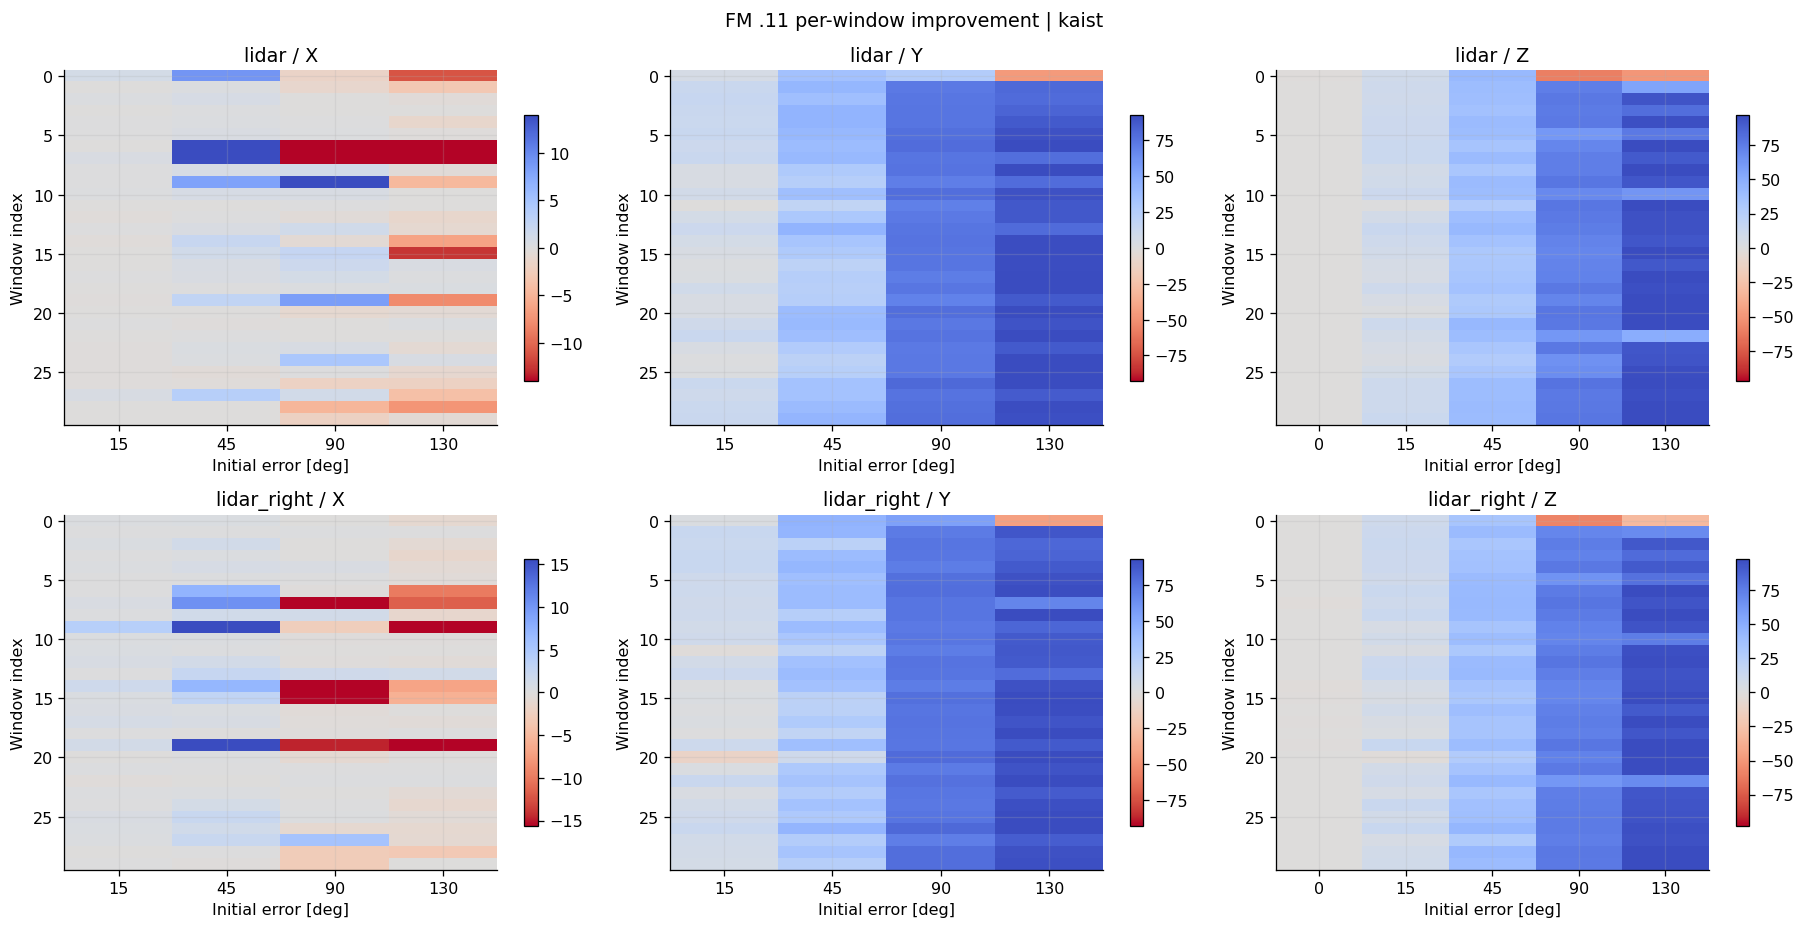

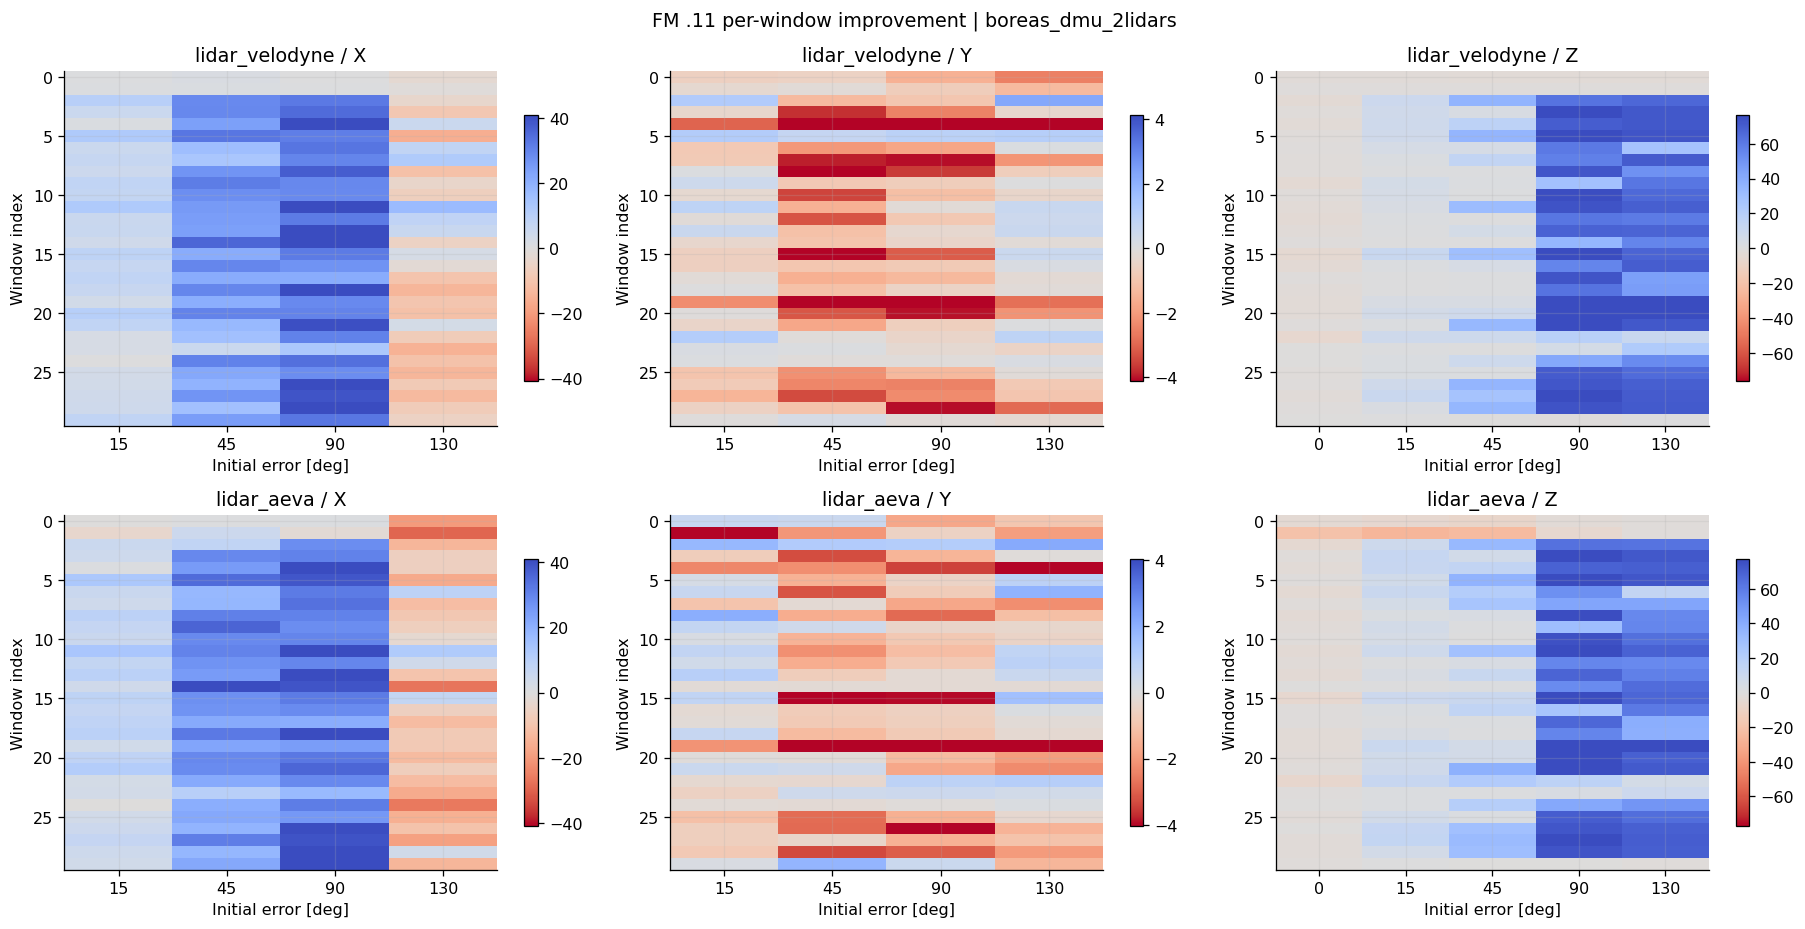

In [21]:
# Heatmaps: paired window/angle recovery, one panel for each LiDAR in each domain.
if not fresh.empty:
    for domain in DOMAINS_PRIMARY:
        lids=keys_of_kind(DOMAIN_WINDOWS[domain][0],"lidar")
        fig,axs=plt.subplots(len(lids),3,figsize=(16,4.1*len(lids)),squeeze=False)
        for ri,lidar in enumerate(lids):
            for ci,axis in enumerate(DIAG_AXES):
                ax=axs[ri,ci]
                part=fresh[(fresh.domain==domain)&(fresh.lidar==lidar)&(fresh.axis==axis)&(fresh.model=="FM .11")]
                piv=part.pivot(index="window",columns="angle_deg",values="improvement_deg")
                vmax=max(1.,float(np.nanpercentile(np.abs(piv.values),95)))
                im=ax.imshow(piv.to_numpy(),aspect="auto",cmap="coolwarm_r",vmin=-vmax,vmax=vmax)
                ax.set(title=f"{lidar} / {axis.upper()}",xlabel="Initial error [deg]",ylabel="Window index")
                ax.set_xticks(np.arange(len(piv.columns)),labels=[str(int(v)) for v in piv.columns])
                fig.colorbar(im,ax=ax,shrink=.75)
        fig.suptitle(f"FM .11 per-window improvement | {domain}")
        fig.tight_layout()
        if SAVE_PLOTS:fig.savefig(OUT/f"09_fm_heatmaps_{domain}.png",dpi=150,bbox_inches="tight")
        if SHOW_PLOTS:plt.show()
        plt.close(fig)

,domain,lidar,axis,angle_deg,median_step_deg,median_cosine,median_improvement_deg,harmful_fraction
0,boreas_dmu_2lidars,lidar_aeva,x,45.0,41.445,0.912,24.960,0.000
1,boreas_dmu_2lidars,lidar_aeva,x,90.0,55.526,0.740,31.537,0.033
2,boreas_dmu_2lidars,lidar_aeva,x,130.0,72.755,0.025,-10.233,0.833
3,boreas_dmu_2lidars,lidar_aeva,y,45.0,3.058,-0.363,-1.032,0.800
4,boreas_dmu_2lidars,lidar_aeva,y,90.0,1.960,-0.534,-0.842,0.867
5,boreas_dmu_2lidars,lidar_aeva,y,130.0,1.832,-0.431,-0.266,0.633
6,boreas_dmu_2lidars,lidar_aeva,z,45.0,11.465,0.951,8.541,0.100
7,boreas_dmu_2lidars,lidar_aeva,z,90.0,69.398,0.992,67.763,0.100
8,boreas_dmu_2lidars,lidar_aeva,z,130.0,64.152,0.966,61.499,0.100
9,boreas_dmu_2lidars,lidar_velodyne,x,45.0,41.748,0.887,24.483,0.000


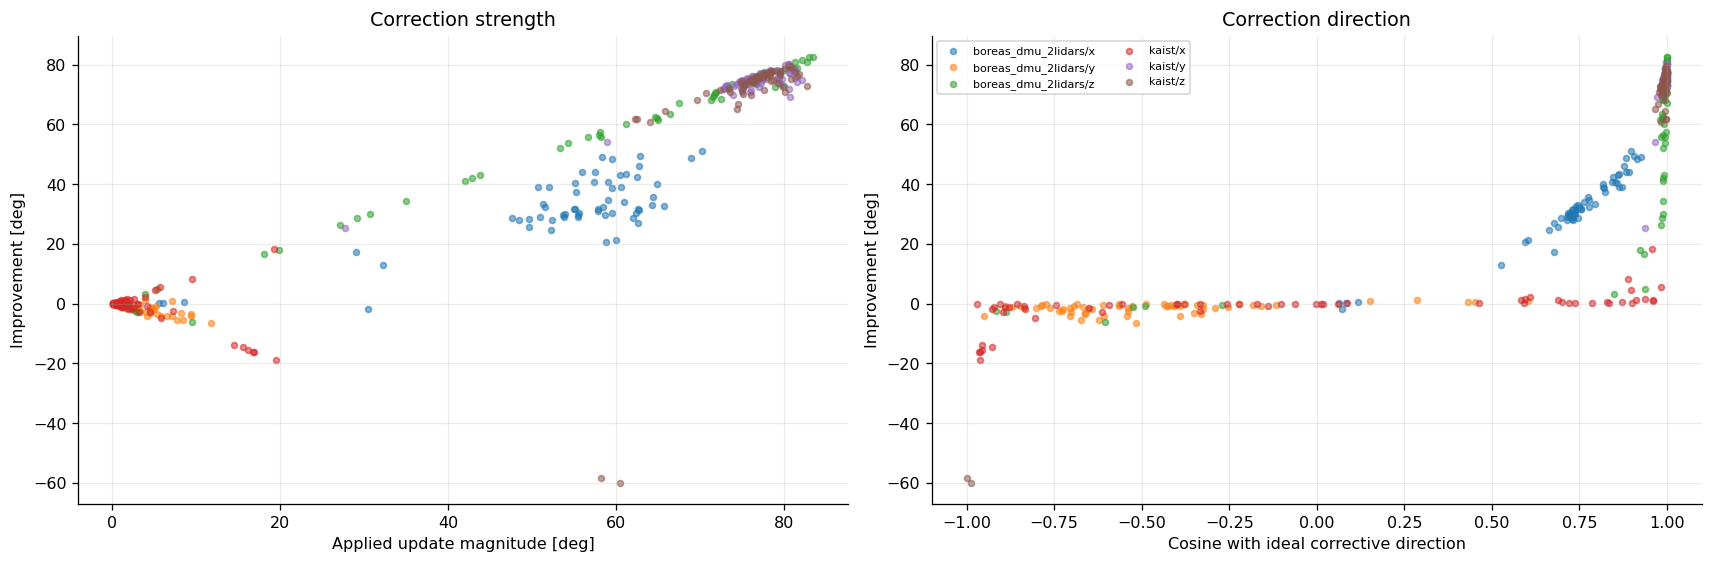

In [22]:
# Where are corrections weak because the model outputs nearly zero, versus pointing wrong?
if not fresh.empty:
    focus=fresh[(fresh.angle_deg.isin([45.,90.,130.]))&(fresh.model=="FM .11")]
    display(focus.groupby(["domain","lidar","axis","angle_deg"],as_index=False).agg(
        median_step_deg=("predicted_step_deg","median"),median_cosine=("cosine","median"),
        median_improvement_deg=("improvement_deg","median"),
        harmful_fraction=("improvement_deg",lambda x:(x<0).mean())).round(3))
    fig,axs=plt.subplots(1,2,figsize=(15,5))
    for (domain,axis),p in focus[focus.angle_deg==90].groupby(["domain","axis"]):
        axs[0].scatter(p.predicted_step_deg,p.improvement_deg,s=14,alpha=.55,label=f"{domain}/{axis}")
        axs[1].scatter(p.cosine,p.improvement_deg,s=14,alpha=.55,label=f"{domain}/{axis}")
    axs[0].set(xlabel="Applied update magnitude [deg]",ylabel="Improvement [deg]",title="Correction strength")
    axs[1].set(xlabel="Cosine with ideal corrective direction",ylabel="Improvement [deg]",title="Correction direction")
    axs[1].legend(fontsize=7,ncol=2)
    finish_plot(fig,"10_magnitude_direction_vs_actual_improvement.png")

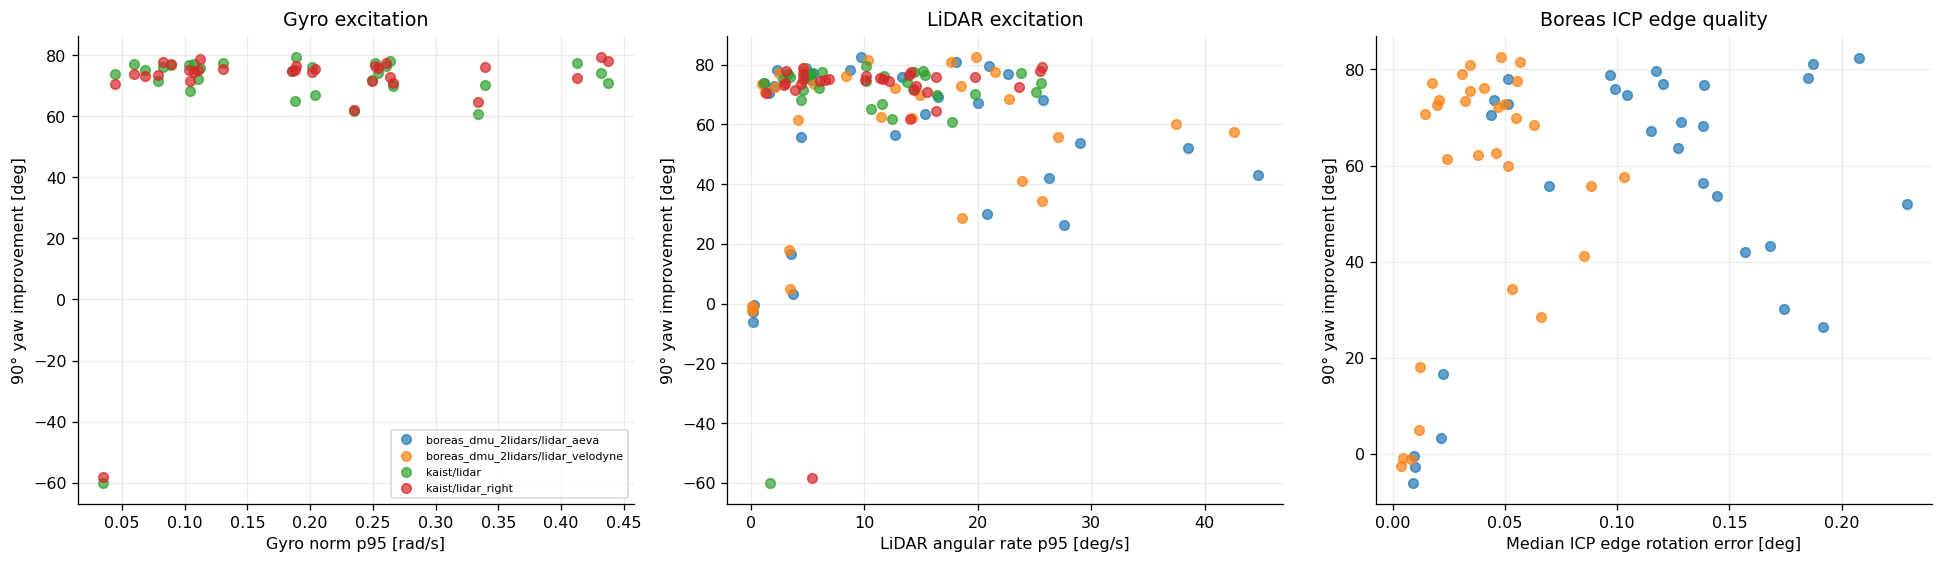

In [23]:
# Relate motion excitation AND Boreas ICP edge quality to FM's per-window performance.
if not fresh.empty:
    feature_pivot=motion_table.pivot_table(index=["domain","window"],columns="metric",values="p95").reset_index()
    joined=fresh.merge(feature_pivot,on=["domain","window"],how="left",validate="many_to_one")
    if not quality.empty:
        joined=joined.merge(quality[["domain","window","lidar","rot_error_med_deg","trans_error_med_m"]],
                            on=["domain","window","lidar"],how="left",validate="many_to_one")
    chosen=joined[(joined.model=="FM .11")&(joined.axis=="z")&(joined.angle_deg==90)]
    fig,axs=plt.subplots(1,3,figsize=(17,5))
    for (domain,lidar),sub in chosen.groupby(["domain","lidar"]):
        gyro_col=next((c for c in joined.columns if c.startswith("imu/") and c.endswith("/gyro/norm")),None)
        if gyro_col is None:
            gyro_col=next((c for c in joined.columns if c.endswith("/gyro/norm") and domain=="boreas_dmu_2lidars"),None)
        if gyro_col:
            axs[0].scatter(sub[gyro_col],sub.improvement_deg,label=f"{domain}/{lidar}",alpha=.7)
        lidar_col=f"{lidar}/lidar/rotation_rate_degps"
        if lidar_col in joined:
            axs[1].scatter(sub[lidar_col],sub.improvement_deg,label=f"{domain}/{lidar}",alpha=.7)
        if "rot_error_med_deg" in sub:
            s=sub.dropna(subset=["rot_error_med_deg"])
            axs[2].scatter(s.rot_error_med_deg,s.improvement_deg,label=f"{domain}/{lidar}",alpha=.7)
    axs[0].set(title="Gyro excitation",xlabel="Gyro norm p95 [rad/s]",ylabel="90° yaw improvement [deg]")
    axs[1].set(title="LiDAR excitation",xlabel="LiDAR angular rate p95 [deg/s]",ylabel="90° yaw improvement [deg]")
    axs[2].set(title="Boreas ICP edge quality",xlabel="Median ICP edge rotation error [deg]",ylabel="90° yaw improvement [deg]")
    axs[0].legend(fontsize=7)
    finish_plot(fig,"11_window_motion_ICP_vs_fm_response.png")
    if SAVE_PLOTS:joined.to_csv(OUT/"fm_response_vs_measured_motion.csv",index=False)

## 7. Chronological convergence: vary **start window** and fault axis

Single-window success is not the same as rollout convergence. This section starts multiple independent Boreas rollouts at different real windows. Each update sees a new physical window. It tracks **0° stability**, accumulated error, and FM-versus-regression differences for X/Y/Z separately. A start-window sweep is essential because the first 10–15 seconds of Boreas were previously uninformative or even harmful in some rollouts.

KAIST chronological evaluation is available **only** when `KAIST_VERIFIED_STARTS_S` contains actual physical starts and passes the stride checks. An index multiplied by five seconds is *not* proof of chronology.

In [24]:
def verified_rollout_indices(domain,start,count):
    windows=DOMAIN_WINDOWS[domain]
    end=min(len(windows),start+count)
    if start<0 or end-start<2: return []
    indices=list(range(start,end))
    if domain=="kaist":
        if KAIST_VERIFIED_STARTS_S is None:return []
        times=np.asarray(KAIST_VERIFIED_STARTS_S,dtype=float)
        if times.shape!=(len(windows),):raise ValueError("KAIST_VERIFIED_STARTS_S must match loaded window count")
        starts=times[indices]
    else:
        starts=DOMAIN_TIMES[domain][indices]
    if np.any(np.abs(np.diff(starts)-WINDOW_STRIDE_S)>1e-3):
        return []   # Never stitch a missing physical window
    return indices

@torch.inference_mode()
def run_model_rollout(domain,lidar,angle,axis,model_name,start,count,*,window_transform=None):
    indices=verified_rollout_indices(domain,start,count)
    if len(indices)<2:return []
    w0=to_device(DOMAIN_WINDOWS[domain][indices[0]])
    reference=w0.current_calibration
    state=inject_rotation_fault(reference,lidar,angle,axis)
    results=[dict(domain=domain,lidar=lidar,angle_deg=angle,axis=axis,model=model_name,
                  start_window=start,step=0,elapsed_s=0.0,error_deg=angle)]
    for step,wi in enumerate(indices,1):
        w=DOMAIN_WINDOWS[domain][wi]
        if window_transform is not None:
            w=window_transform(w)
        w=to_device(w)
        for key in reference:
            torch.testing.assert_close(w.current_calibration[key].transform,reference[key].transform,atol=2e-5,rtol=2e-5)
        pred=model_predict(MODELS[model_name],w,state)
        state=apply_single_rotation_update(state,pred,lidar)
        err=float(so3_error_deg(state[lidar].transform,reference[lidar].transform).item())
        results.append(dict(domain=domain,lidar=lidar,angle_deg=angle,axis=axis,model=model_name,
            start_window=start,step=step,elapsed_s=step*WINDOW_STRIDE_S,error_deg=err))
    return results

In [25]:
rollout_rows=[]
if RUN_BOREAS_START_SWEEP:
    for domain in ("boreas_dmu_2lidars",):
        jobs=[(domain,lidar,angle,axis,model,start,ROLLOUT_LENGTH_05)
            for lidar in keys_of_kind(DOMAIN_WINDOWS[domain][0],"lidar")
            for angle in ROLLOUT_ANGLES_DEG
            for axis in (("z",) if angle==0 else ROLLOUT_AXES_05)
            for model in MODELS
            for start in ROLLOUT_STARTS_05 if verified_rollout_indices(domain,start,ROLLOUT_LENGTH_05)]
        for args in tqdm(jobs,desc=f"Chronological start sweep {domain}"):
            rollout_rows.extend(run_model_rollout(*args))
rollouts=pd.DataFrame(rollout_rows)
if not rollouts.empty:
    endings=rollouts.sort_values("step").groupby(["domain","lidar","model","axis","angle_deg","start_window"],as_index=False).tail(1)
    display(endings.groupby(["lidar","model","axis","angle_deg"],as_index=False).agg(
        median_final_deg=("error_deg","median"),worst_final_deg=("error_deg","max"),
        within_10deg=("error_deg",lambda x:(x<10).mean()),
        within_20deg=("error_deg",lambda x:(x<20).mean()),n_starts=("error_deg","size")).round(3))
    if SAVE_PLOTS:
        rollouts.to_csv(OUT/"multi_start_boreas_rollouts.csv",index=False)
        endings.to_csv(OUT/"multi_start_rollout_endings.csv",index=False)

Chronological start sweep boreas_dmu_2lidars:   0%|          | 0/160 [00:00<?, ?it/s]

,lidar,model,axis,angle_deg,median_final_deg,worst_final_deg,within_10deg,within_20deg,n_starts
0,lidar_aeva,FM .11,x,45.0,15.425,17.171,0.00,1.00,4
1,lidar_aeva,FM .11,x,90.0,79.713,84.226,0.00,0.00,4
2,lidar_aeva,FM .11,x,130.0,128.016,150.053,0.00,0.00,4
3,lidar_aeva,FM .11,y,45.0,56.019,61.640,0.00,0.00,4
4,lidar_aeva,FM .11,y,90.0,95.126,97.418,0.00,0.00,4
5,lidar_aeva,FM .11,y,130.0,131.358,134.402,0.00,0.00,4
6,lidar_aeva,FM .11,z,0.0,7.968,8.049,1.00,1.00,4
7,lidar_aeva,FM .11,z,45.0,8.137,14.517,0.75,1.00,4
8,lidar_aeva,FM .11,z,90.0,8.772,20.280,0.50,0.75,4
9,lidar_aeva,FM .11,z,130.0,27.462,34.215,0.00,0.00,4


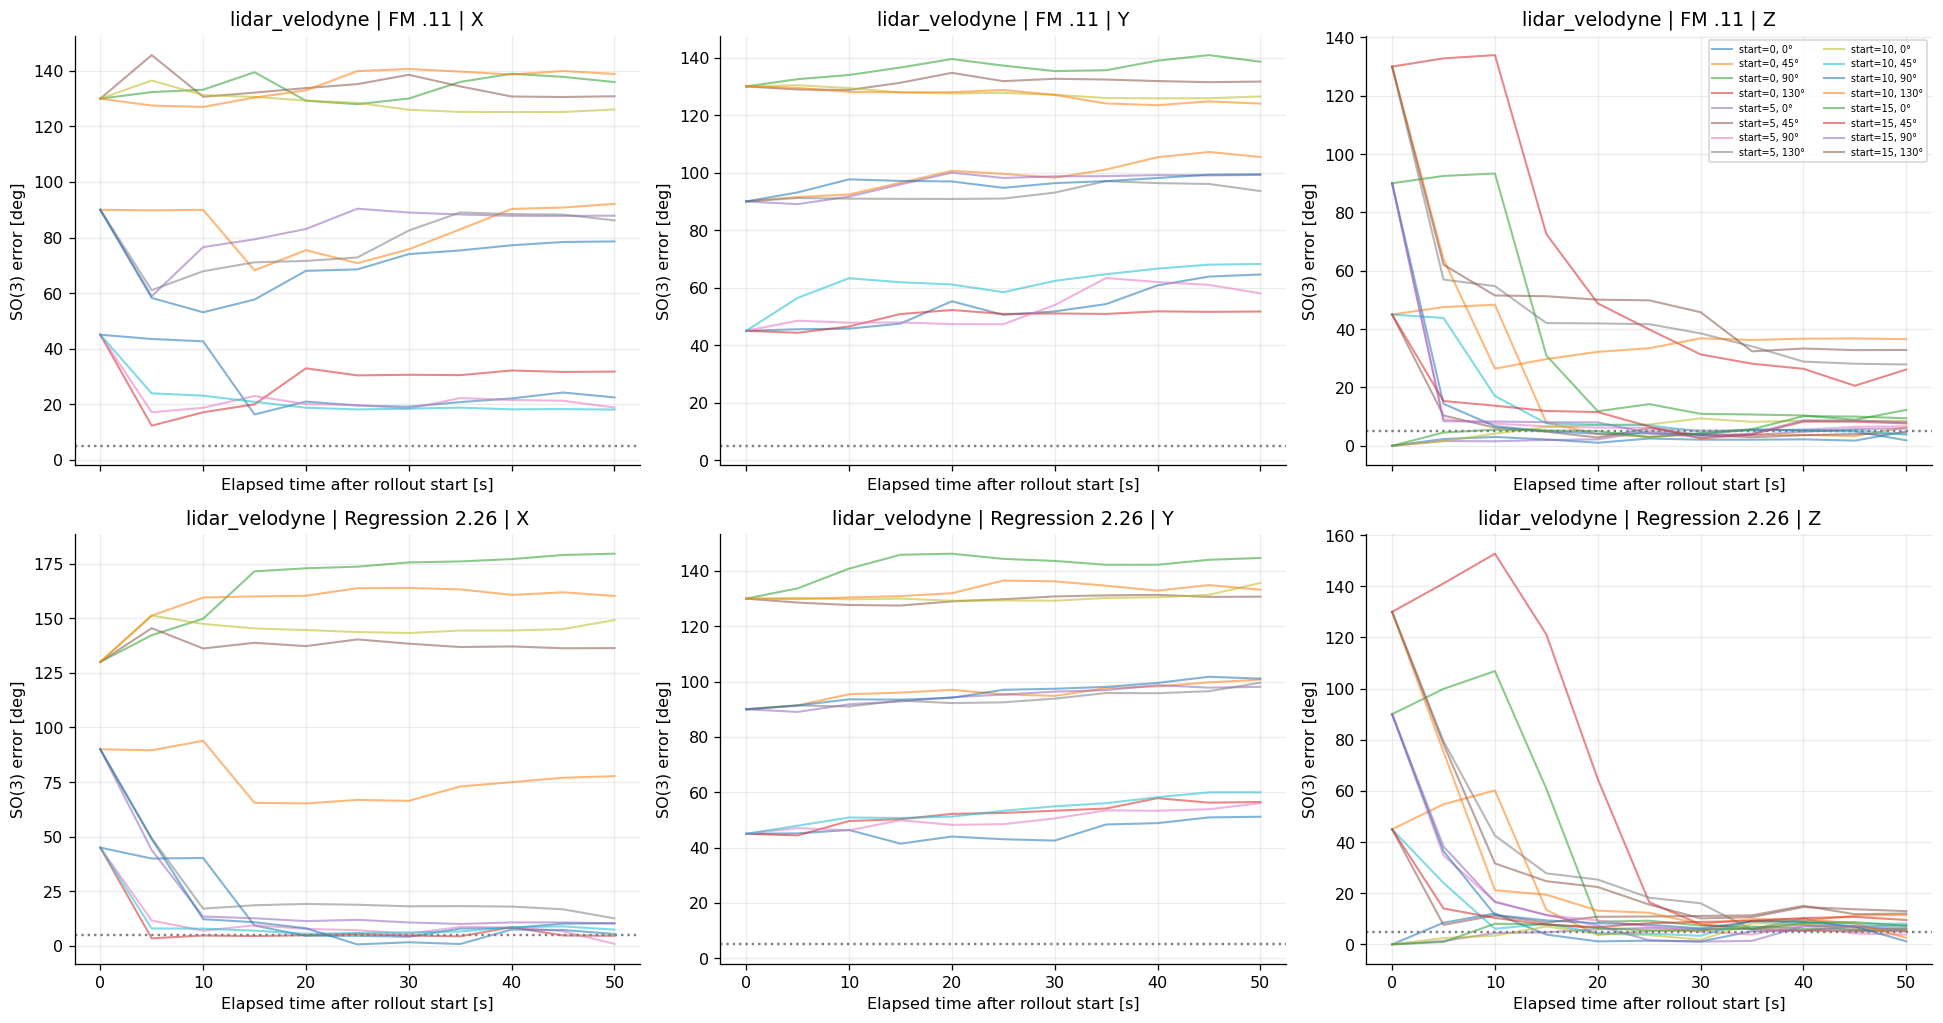

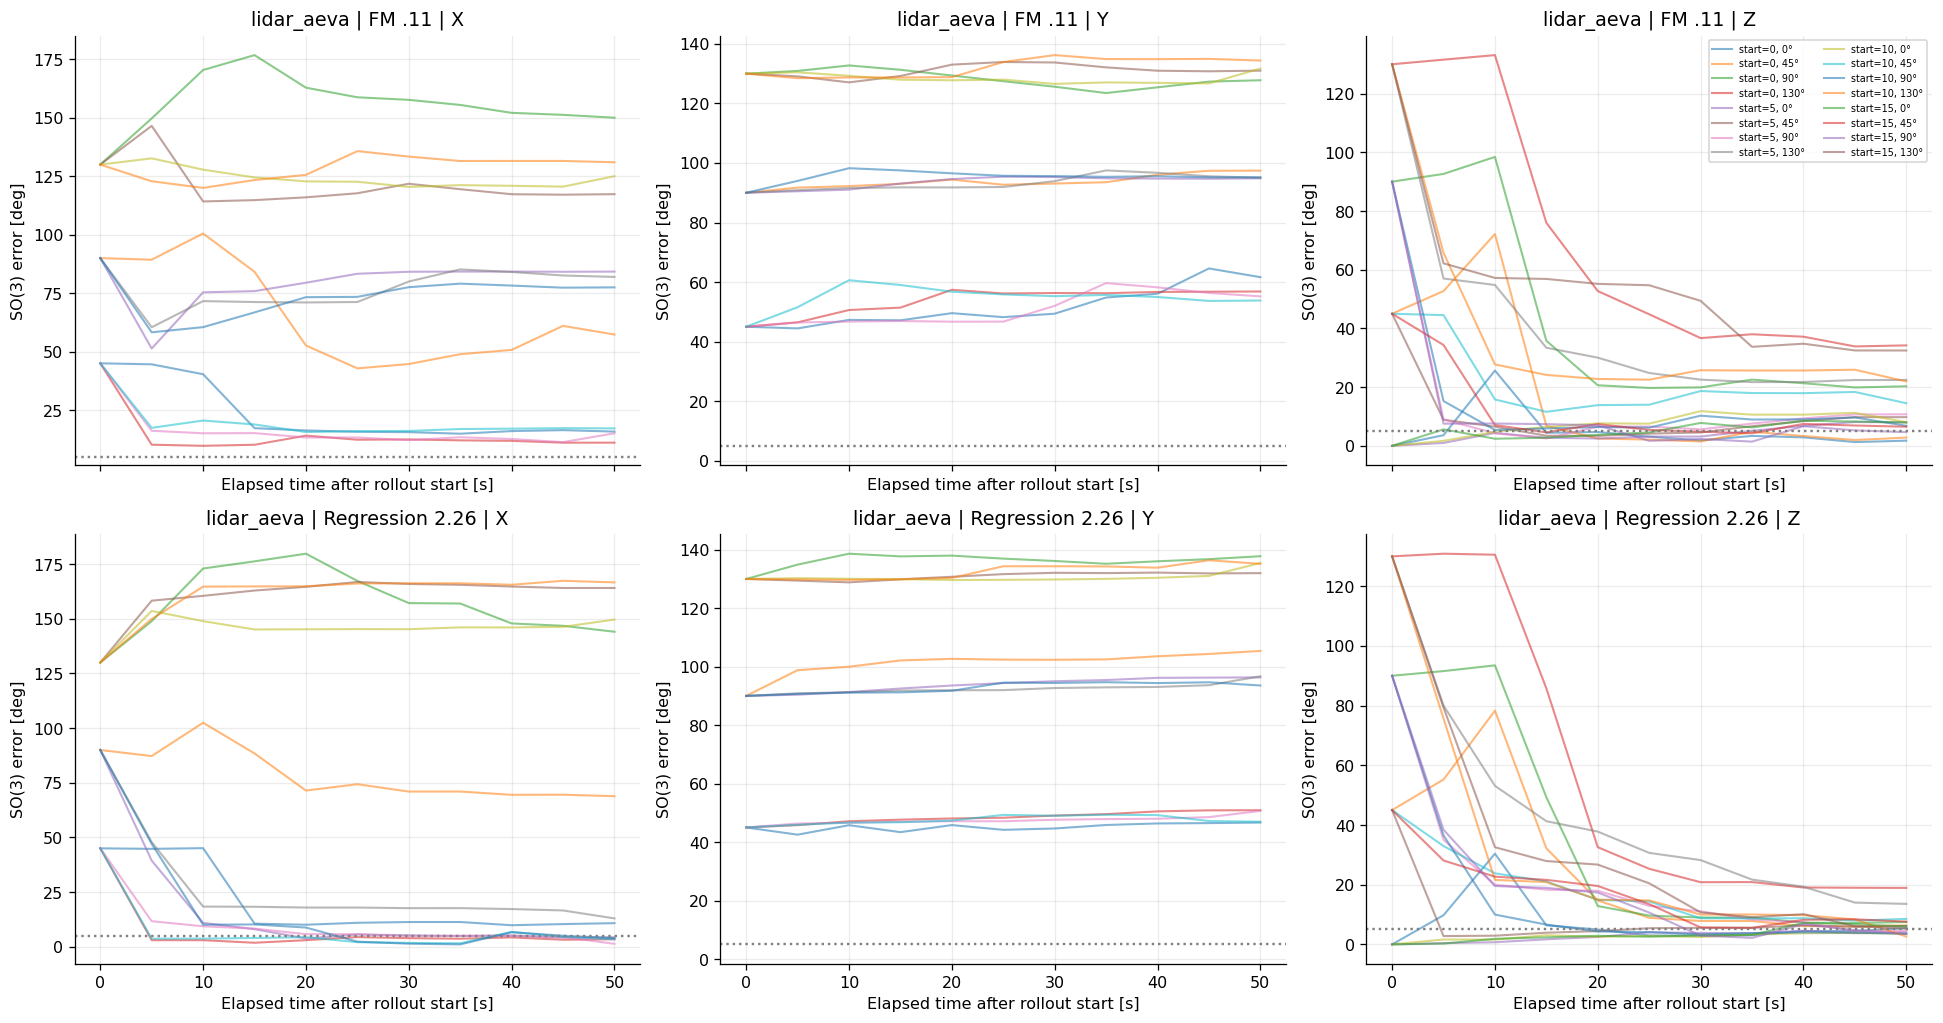

In [26]:
if not rollouts.empty:
    for lidar in keys_of_kind(DOMAIN_WINDOWS["boreas_dmu_2lidars"][0],"lidar"):
        fig,axs=plt.subplots(2,3,figsize=(17,9),sharex=True)
        for col,axis in enumerate(ROLLOUT_AXES_05):
            for row,model_name in enumerate(MODELS):
                ax=axs[row,col]
                part=rollouts[(rollouts.lidar==lidar)&(rollouts.axis==axis)&(rollouts.model==model_name)]
                for (start,angle),g in part.groupby(["start_window","angle_deg"]):
                    if angle not in (0.,45.,90.,130.):continue
                    ax.plot(g.elapsed_s,g.error_deg,alpha=.55,lw=1.3,
                            label=f"start={start}, {angle:g}°")
                ax.axhline(5.,c="gray",ls=":")
                ax.set(title=f"{lidar} | {model_name} | {axis.upper()}",xlabel="Elapsed time after rollout start [s]",
                       ylabel="SO(3) error [deg]")
                if row==0 and col==2:ax.legend(fontsize=6,ncol=2)
        finish_plot(fig,f"12_start_window_rollouts_{lidar}.png")

## 8. Topology dependency and optional token-count intervention (Boreas)

Here topology comparisons use the **same Boreas physical windows and fault**. The `2 IMUs + 1 LiDAR` case has a much larger IMU-token share than `1 IMU + 2 LiDARs`. Lowering the IMU cap is a diagnostic **subsampling of real measurements**, not an assertion that fewer IMU samples are physically preferable or that attention weights equal token proportions.

In [27]:
TOPOLOGY_TEST_DOMAINS=("boreas_dmu_2lidars","boreas_2imu_velodyne","boreas_2imu_aeva_lidar","boreas_four")
TOPOLOGY_TEST_WINDOWS=(0,5,10,15,20,25)
TOPOLOGY_TEST_ANGLES=(0.,45.,90.,130.)
topology_rows=[]
if RUN_TOPOLOGY_COMPARISON:
    jobs=[]
    for domain in TOPOLOGY_TEST_DOMAINS:
        for wi in TOPOLOGY_TEST_WINDOWS:
            if wi>=len(DOMAIN_WINDOWS[domain]):continue
            for key in keys_of_kind(DOMAIN_WINDOWS[domain][wi],"lidar"):
                for angle in TOPOLOGY_TEST_ANGLES:
                    for model in MODELS:
                        jobs.append((domain,wi,key,angle,"z",model))
    for args in tqdm(jobs,desc="Matched Boreas topology comparison"):
        topology_rows.append(run_fresh_case(*args))
topology_cases=pd.DataFrame(topology_rows)
if not topology_cases.empty:
    display(topology_cases.groupby(["domain","lidar","model","angle_deg"],as_index=False).agg(
        final_median=("final_deg","median"),improvement_median=("improvement_deg","median"),
        improved_fraction=("improvement_deg",lambda x:(x>0).mean())).round(3))
    if SAVE_PLOTS:topology_cases.to_csv(OUT/"matched_topology_one_step.csv",index=False)

Matched Boreas topology comparison:   0%|          | 0/288 [00:00<?, ?it/s]

,domain,lidar,model,angle_deg,final_median,improvement_median,improved_fraction
0,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,0.0,1.060,-1.060,0.000
1,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,45.0,43.085,1.915,0.833
2,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,90.0,97.645,-7.645,0.167
3,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,130.0,131.036,-1.036,0.167
4,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,0.0,3.666,-3.666,0.000
5,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,45.0,42.113,2.887,0.667
6,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,90.0,91.446,-1.446,0.000
7,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,130.0,131.252,-1.252,0.167
8,boreas_2imu_velodyne,lidar_velodyne,FM .11,0.0,1.195,-1.195,0.000
9,boreas_2imu_velodyne,lidar_velodyne,FM .11,45.0,42.927,2.073,0.833


In [28]:
# Optional physically matched topology ROLLOUTS on exactly the same Boreas windows.
# Compare a shared faulty LiDAR, holding its nominal extrinsic and fault axis fixed.
topology_rollout_rows=[]
if RUN_TOPOLOGY_ROLLOUT:
    topology_pairs={
        "lidar_velodyne":("boreas_dmu_2lidars","boreas_2imu_velodyne","boreas_four"),
        "lidar_aeva":("boreas_dmu_2lidars","boreas_2imu_aeva_lidar","boreas_four"),
    }
    jobs=[]
    for lidar,domains in topology_pairs.items():
        for domain in domains:
            for start in (0,10):
                if not verified_rollout_indices(domain,start,10):continue
                for angle in (0.,45.,90.,130.):
                    for model in MODELS:
                        jobs.append((domain,lidar,angle,"z",model,start,10))
    for args in tqdm(jobs,desc="Matched topology chronological LiDAR rollouts"):
        topology_rollout_rows.extend(run_model_rollout(*args))
topology_rollouts=pd.DataFrame(topology_rollout_rows)
if not topology_rollouts.empty:
    endings=(topology_rollouts.sort_values("step").groupby(
        ["domain","lidar","angle_deg","axis","model","start_window"],as_index=False).tail(1))
    display(endings.groupby(["domain","lidar","model","angle_deg"],as_index=False).error_deg.median().round(3))
    if SAVE_PLOTS:topology_rollouts.to_csv(OUT/"optional_topology_chronological_rollouts.csv",index=False)

Matched topology chronological LiDAR rollouts:   0%|          | 0/96 [00:00<?, ?it/s]

,domain,lidar,model,angle_deg,error_deg
0,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,0.0,5.633
1,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,45.0,37.759
2,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,90.0,138.247
3,boreas_2imu_aeva_lidar,lidar_aeva,FM .11,130.0,161.186
4,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,0.0,21.618
5,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,45.0,38.690
6,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,90.0,113.529
7,boreas_2imu_aeva_lidar,lidar_aeva,Regression 2.26,130.0,127.598
8,boreas_2imu_velodyne,lidar_velodyne,FM .11,0.0,7.834
9,boreas_2imu_velodyne,lidar_velodyne,FM .11,45.0,31.054


In [29]:
# Optional: uniformly thin *both* gyro and accel streams of each IMU while preserving time coverage.
def limit_imu_tokens(window,cap):
    if cap<2:raise ValueError("cap must be >=2")
    streams={}
    for name,s in window.streams.items():
        if kind_of(window.metadata[name])=="lidar" or s.values.shape[1]<=cap:
            streams[name]=s
            continue
        inds=torch.linspace(0,s.values.shape[1]-1,cap,device=s.values.device).round().long().unique(sorted=True)
        streams[name]=replace(s,values=s.values[:,inds],timestamps=s.timestamps[:,inds],sample_mask=s.sample_mask[:,inds])
    return replace(window,streams=streams)

cap_rows=[]
if RUN_IMU_CAP_ABLATION:
    assert MAX_IMU_SAMPLES_PER_WINDOW>=max(OPTIONAL_IMU_CAPS)
    jobs=[]
    for domain in ("boreas_dmu_2lidars","boreas_2imu_velodyne"):
        for wi in OPTIONAL_IMU_CAP_WINDOWS:
            if wi>=len(DOMAIN_WINDOWS[domain]):continue
            for key in keys_of_kind(DOMAIN_WINDOWS[domain][wi],"lidar"):
                for cap in OPTIONAL_IMU_CAPS:
                    w=limit_imu_tokens(DOMAIN_WINDOWS[domain][wi],cap)
                    for model in MODELS:
                        for angle in (0.,45.,90.):
                            jobs.append((domain,wi,key,angle,model,cap,w))
    for domain,wi,key,angle,model,cap,w in tqdm(jobs,desc="Reversible IMU-token cap ablation"):
        r=run_fresh_case(domain,wi,key,angle,"z",model,window_override=w)
        r["imu_cap"]=cap
        cap_rows.append(r)
cap_results=pd.DataFrame(cap_rows)
if not cap_results.empty:
    display(cap_results.groupby(["domain","model","lidar","imu_cap","angle_deg"],as_index=False).agg(
        final_median=("final_deg","median"),improvement_median=("improvement_deg","median")).round(3))
    if SAVE_PLOTS:cap_results.to_csv(OUT/"optional_imu_token_cap_ablation.csv",index=False)

Reversible IMU-token cap ablation:   0%|          | 0/540 [00:00<?, ?it/s]

,domain,model,lidar,imu_cap,angle_deg,final_median,improvement_median
0,boreas_2imu_velodyne,FM .11,lidar_velodyne,100,0.0,1.762,-1.762
1,boreas_2imu_velodyne,FM .11,lidar_velodyne,100,45.0,44.419,0.581
2,boreas_2imu_velodyne,FM .11,lidar_velodyne,100,90.0,90.496,-0.496
3,boreas_2imu_velodyne,FM .11,lidar_velodyne,200,0.0,2.159,-2.159
4,boreas_2imu_velodyne,FM .11,lidar_velodyne,200,45.0,42.842,2.159
...,...,...,...,...,...,...,...
85,boreas_dmu_2lidars,Regression 2.26,lidar_velodyne,500,45.0,30.623,14.377
86,boreas_dmu_2lidars,Regression 2.26,lidar_velodyne,500,90.0,37.672,52.328
87,boreas_dmu_2lidars,Regression 2.26,lidar_velodyne,700,0.0,2.244,-2.244
88,boreas_dmu_2lidars,Regression 2.26,lidar_velodyne,700,45.0,19.025,25.975


## 9. Optional LiDAR-oracle diagnostic to isolate ICP (OFF by default)

**This is intentionally not a valid independent calibration benchmark.** It replaces only the current window's LiDAR relative motions with increments from `sequence.lidar_poses(source=...)`, retaining exactly the same timestamps, same other sensor measurements, and same injected calibration fault. If the model improves substantially with reference-derived increments, independent ICP odometry quality/conventions are implicated; if not, look at frame geometry, IMUs, tokenization, or model conditioning. Never mix oracle-derived rows into baseline transfer scores or training data.

In [30]:
@torch.inference_mode()
def substitute_reference_lidar_in_window(window, key, wi):
    if key not in BOREAS_GT_BY_SOURCE:
        source={"lidar_velodyne":"velodyne","lidar_aeva":"aeva"}[key]
        BOREAS_GT_BY_SOURCE[key]=boreas_sequence.lidar_poses(source=source)
    gt=BOREAS_GT_BY_SOURCE[key]
    s=window.streams[key]
    absolute_t0=common_start+int(round(boreas_window_starts[wi]*1e9))
    starts=absolute_t0+np.rint(s.interval_start_timestamps[0].cpu().numpy()*1e9).astype(np.int64)
    ends=absolute_t0+np.rint(s.timestamps[0].cpu().numpy()*1e9).astype(np.int64)
    query=np.unique(np.r_[starts,ends])
    matched=gt.match(query,tolerance_s=.15,interpolate=True,max_gap_s=.4)
    delta=np.linalg.solve(matched[np.searchsorted(query,starts)],matched[np.searchsorted(query,ends)])
    valid_transform(f"oracle/{key}",delta)
    replacement=replace(s,values=torch.as_tensor(delta,dtype=s.values.dtype).unsqueeze(0))
    new_streams=dict(window.streams);new_streams[key]=replacement
    return replace(window,streams=new_streams)

oracle_rows=[]
if RUN_LIDAR_GT_ORACLE:
    jobs=[]
    for wi in OPTIONAL_ORACLE_WINDOWS:
        if wi>=len(DOMAIN_WINDOWS["boreas_dmu_2lidars"]):continue
        for key in keys_of_kind(DOMAIN_WINDOWS["boreas_dmu_2lidars"][wi],"lidar"):
            for angle in OPTIONAL_ORACLE_ANGLES:
                for model in MODELS:
                    jobs.append((wi,key,angle,model))
    for wi,key,angle,model in tqdm(jobs,desc="Explicit GT-derived LiDAR oracle check"):
        original=DOMAIN_WINDOWS["boreas_dmu_2lidars"][wi]
        try: altered=substitute_reference_lidar_in_window(original,key,wi)
        except ValueError as exc:
            print("SKIP oracle window",wi,key,exc);continue
        for variant,window in (("ICP",original),("GT_ORACLE_NOT_BENCHMARK",altered)):
            r=run_fresh_case("boreas_dmu_2lidars",wi,key,angle,"z",model,window_override=window)
            r["source_variant"]=variant
            oracle_rows.append(r)
oracle_results=pd.DataFrame(oracle_rows)
if not oracle_results.empty:
    base=oracle_results[oracle_results.source_variant=="ICP"]
    oracle=oracle_results[oracle_results.source_variant=="GT_ORACLE_NOT_BENCHMARK"]
    paired=base.merge(oracle,on=["domain","window","lidar","angle_deg","axis","model"],suffixes=("_icp","_oracle"),validate="one_to_one")
    paired["oracle_minus_icp_final_deg"]=paired.final_deg_oracle-paired.final_deg_icp
    display(paired.groupby(["lidar","model","angle_deg"],as_index=False).oracle_minus_icp_final_deg.median().round(3))
    if SAVE_PLOTS:paired.to_csv(OUT/"optional_oracle_vs_icp_diagnostic_only.csv",index=False)

Explicit GT-derived LiDAR oracle check:   0%|          | 0/60 [00:00<?, ?it/s]

,lidar,model,angle_deg,oracle_minus_icp_final_deg
0,lidar_aeva,FM .11,0.0,-0.547
1,lidar_aeva,FM .11,45.0,-1.761
2,lidar_aeva,FM .11,90.0,-0.121
3,lidar_aeva,Regression 2.26,0.0,-0.177
4,lidar_aeva,Regression 2.26,45.0,0.577
5,lidar_aeva,Regression 2.26,90.0,0.036
6,lidar_velodyne,FM .11,0.0,0.300
7,lidar_velodyne,FM .11,45.0,-0.037
8,lidar_velodyne,FM .11,90.0,-0.007
9,lidar_velodyne,Regression 2.26,0.0,0.137


## 10. Export experiment manifest and interpret outcomes

A useful decision tree:

| Observation | Most relevant next action |
|---|---|
| IMU samples cover only part of each 5 s window | Fix timestamp conversion/window selection before modeling |
| Gyro–LiDAR rotation disagreement high (especially when edge-inverted control is smaller) | Audit transform direction, timestamp convention, and calibration chain |
| LiDAR fresh corrections good but start-sensitive rollouts unstable | Add uncertainty/observability gating, per-window step control, or train on broader motion patterns |
| Model results change greatly with IMU cap | Investigate token balancing and modality-aware pooling; compare training-time token distribution |
| ICP-vs-reference edge errors explain failure windows, or GT oracle improves results | Design realistic odometry-error augmentation and inspect registration pipeline |
| Boreas fails even with consistent sensors and GT diagnostic | Domain-specific geometry/motion distributions, topology conditioning, and mixed KAIST+Boreas training become stronger candidates |

**Training next:** preserve FM .11 and regression 2.26 as frozen baselines. If fine-tuning on Boreas, use geographically/temporally separated train/validation windows and, ideally, leave an *entire additional Boreas sequence* untouched for final generalization. Never train on an oracle-derived input if the evaluation is meant to test independent ICP odometry.

In [31]:
manifest={
    "run":RUN_NAME, "kaist_sequence":KAIST_SEQUENCE,
    "kaist_training_split_note":"Urban08 is seen train in notebook55; confirm FM.11 metadata separately",
    "kaist_rig_source":KAIST_REFERENCE_SOURCE,
    "boreas_sequence":BOREAS_SEQUENCE,"boreas_loaded_topology":"all_four",
    "boreas_full_icp_input":True,"window_s":WINDOW_DURATION_S,"stride_s":WINDOW_STRIDE_S,
    "imu_cap":MAX_IMU_SAMPLES_PER_WINDOW,"kaist_imu_cap":KAIST_MAX_SAMPLES_PER_SENSOR,
    "model_checkpoints":{"FM .11":str(checkpoint_path),
                         "Regression 2.26":str(REGRESSION_CHECKPOINT)},
    "checkpoint_epochs":{"FM .11":fm_metadata.get("epoch"),
                         "Regression 2.26":regression_metadata.get("epoch") if RUN_REGRESSION else None},
    "domains":{name:{"windows":len(w),"keys":list(w[0].current_calibration)} for name,w in DOMAIN_WINDOWS.items()},
    "angles_deg":DIAG_ANGLES_DEG,"axes":DIAG_AXES,"rollout_start_windows":ROLLOUT_STARTS_05,
    "experiment_switches":{
        "consistency":RUN_CONSISTENCY_SWEEP,"ICP_quality":RUN_BOREAS_GT_QUALITY,
        "one_step":RUN_ALL_WINDOW_ONE_STEP,"rollout_start_sweep":RUN_BOREAS_START_SWEEP,
        "topology":RUN_TOPOLOGY_COMPARISON,"topology_rollout":RUN_TOPOLOGY_ROLLOUT,"imu_cap":RUN_IMU_CAP_ABLATION,
        "GT_oracle_diagnostic":RUN_LIDAR_GT_ORACLE},
    "limitations":["Boreas extrinsics are nominal reference, not independently verified truth",
        "No Applanix poses enter baseline model inference",
        "KAIST physical continuity unavailable unless verified starts supplied",
        "Near-180-degree SO(3) branches can mislead single-step improvement metrics",
        "All source measurements remain unchanged; test-time selection changes only in RAM"],
}
if SAVE_PLOTS:
    (OUT/"05_experiment_manifest.json").write_text(json.dumps(manifest,indent=2,default=str))
print("05 diagnostics finished. Outputs:",OUT)

05 diagnostics finished. Outputs: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/kaist_boreas_lidar_domain_diagnostics_05
